In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Import the data
* Import data that describe countries in one point

In [2]:
one_point_countries = pd.read_parquet('../data/one_point_countries.parquet')

In [3]:
one_point_countries.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,0.097090,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,0.530756,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,0.146086,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-0.373023,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-0.624667,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR


### Search outliers
* Look for outliers
* Plot boxplot for every feature

In [4]:
def detect_outliers_in_dataframe(df, iqr_multiplier=1.5):
    outlier_report = {}

    # Excluye columnas no numéricas
    numeric_cols = df.select_dtypes(include=[np.number]).columns

    for idx, row in df.iterrows():
        country_name = row["Country"]
        outlier_cols = []

        for col in numeric_cols:
            value = row[col]
            col_series = df[col].dropna()

            # Calcula los límites usando IQR
            q1 = np.percentile(col_series, 25)
            q3 = np.percentile(col_series, 75)
            iqr = q3 - q1
            lower_bound = q1 - iqr_multiplier * iqr
            upper_bound = q3 + iqr_multiplier * iqr

            if value < lower_bound or value > upper_bound:
                outlier_cols.append(col)

        outlier_report[country_name] = outlier_cols

    return outlier_report


In [5]:
outliers = detect_outliers_in_dataframe(one_point_countries)


In [6]:
def outlier_dict_to_df(outlier_dict):
    data = [{"Country": country, "Outlier_Count": len(cols)} for country, cols in outlier_dict.items()]
    return pd.DataFrame(data)

In [7]:
from collections import Counter

In [8]:
def rank_outlier_variables(outlier_dict, exclude_columns={"Year"}):
    counter = Counter()
    for macro_list in outlier_dict.values():
        filtered_macros = [col for col in macro_list if col not in exclude_columns]
        counter.update(filtered_macros)

    sorted_macros = sorted(counter.items(), key=lambda x: x[1], reverse=True)

    print("📊 Ranking de macroeconómicos con outliers (por número de países):\n")
    for macro, count in sorted_macros:
        print(f"{macro}: {count} países")

In [9]:
rank_outlier_variables(outliers)

📊 Ranking de macroeconómicos con outliers (por número de países):

cpi_min: 17 países
govermment_effective__cv: 16 países
rule_of_law__cv: 13 países
cpi_median: 12 países
investment_median: 12 países
investment_min: 12 países
gdp_median: 12 países
gdp_min: 12 países
investment_mean: 11 países
investment_std: 11 países
investment_max: 11 países
investment_last: 11 países
gdp_max: 11 países
gdp_last: 11 países
gov_exp_std: 10 países
gov_exp_trend: 10 países
investment_trend: 10 países
gdp_mean: 10 países
gdp_std: 10 países
gdp_trend: 10 países
cpi_mean: 9 países
govermment_effective__growth: 9 países
gov_exp_mean: 9 países
gov_exp_median: 9 países
gov_exp_min: 9 países
gov_exp_max: 9 países
gov_exp_last: 9 países
priv_cred_mean: 9 países
priv_cred_median: 9 países
priv_cred_std: 9 países
priv_cred_min: 9 países
priv_cred_max: 9 países
priv_cred_last: 9 países
priv_cred_trend: 9 países
urban_pop_kurtosis: 9 países
labor_force_trend: 8 países
agr_land_growth: 8 países
inflation__growth: 8 

In [10]:
def pareto_variables_with_countries(outlier_dict, threshold=0.8, exclude_columns={"Year"}):
    from collections import Counter, defaultdict
    import pandas as pd

    # Paso 1: contar ocurrencias por variable
    counter = Counter()
    variable_to_countries = defaultdict(list)

    for country, macro_list in outlier_dict.items():
        for var in macro_list:
            if var not in exclude_columns:
                counter[var] += 1
                variable_to_countries[var].append(country)

    # Paso 2: crear DataFrame ordenado por frecuencia
    df = pd.DataFrame(counter.items(), columns=["Variable", "Outlier_Count"])
    df = df.sort_values(by="Outlier_Count", ascending=False).reset_index(drop=True)

    # Paso 3: aplicar regla de Pareto
    total_outliers = df["Outlier_Count"].sum()
    df["Cumulative_Outliers"] = df["Outlier_Count"].cumsum()
    df["Cumulative_%"] = df["Cumulative_Outliers"] / total_outliers

    pareto_df = df[df["Cumulative_%"] <= threshold].copy()

    if not pareto_df.empty and pareto_df["Cumulative_%"].iloc[-1] < threshold:
        next_row = df.iloc[len(pareto_df)]
        pareto_df = pd.concat([pareto_df, next_row.to_frame().T], ignore_index=True)

    pareto_df["Cumulative_%"] = pd.to_numeric(pareto_df["Cumulative_%"], errors="coerce") * 100
    pareto_df["Cumulative_%"] = pareto_df["Cumulative_%"].round(2)

    # Paso 4: agregar países responsables
    pareto_df["Countries"] = pareto_df["Variable"].apply(lambda var: variable_to_countries[var])

    return pareto_df

In [11]:
pareto_result = pareto_variables_with_countries(outliers, threshold=0.8)

In [12]:
pareto_result

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%,Countries
0,cpi_min,17,17,2.28,"[Australia, Brazil, Canada, Chile, Colombia, I..."
1,govermment_effective__cv,16,33,4.44,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
2,rule_of_law__cv,13,46,6.18,"[Brazil, Bulgaria, Colombia, Greece, India, Me..."
3,cpi_median,12,58,7.80,"[Brazil, Canada, Chile, India, Israel, Malaysi..."
4,investment_min,12,70,9.41,"[Chile, Colombia, Hungary, India, Japan, Mexic..."
...,...,...,...,...,...
75,priv_cred_growth,4,583,78.36,"[Cyprus, India, Philippines, Turkey]"
76,gov_exp_skew,4,587,78.90,"[Croatia, Israel, Thailand, Turkey]"
77,reserves_median,4,591,79.44,"[Czech, India, Japan, Thailand]"
78,agr_land_skew,3,594,79.84,"[Belgium, Estonia, Malaysia]"


In [13]:
def extract_unique_countries(pareto_df, column_name="Countries"):
    all_countries = []

    for country_list in pareto_df[column_name]:
        all_countries.extend(country_list)

    unique_countries = sorted(set(all_countries))
    return unique_countries

In [14]:
unique_countries = extract_unique_countries(pareto_result)

In [15]:
unique_countries

['Australia',
 'Belgium',
 'Brazil',
 'Bulgaria',
 'Canada',
 'Chile',
 'Colombia',
 'Croatia',
 'Cyprus',
 'Czech',
 'Denmark',
 'Estonia',
 'France',
 'Germany',
 'Greece',
 'Hungary',
 'Iceland',
 'India',
 'Ireland',
 'Israel',
 'Japan',
 'Latvia',
 'Lithuania',
 'Luxembourg',
 'Malaysia',
 'Malta',
 'Mexico',
 'Netherlands',
 'New Zealand',
 'Norway',
 'Paraguay',
 'Peru',
 'Philippines',
 'Poland',
 'Portugal',
 'Romania',
 'Russia',
 'Serbia',
 'Singapore',
 'Slovakia',
 'Slovenia',
 'South Africa',
 'South Korea',
 'Spain',
 'Sweden',
 'Switzerland',
 'Thailand',
 'Turkey',
 'USA']

In [16]:
len(unique_countries)

49

* Make no sense, we have 53 countries and with this idea we want to eliminate 49
* So apply winsorization, robust scaler and log transformation one time and see the countries that are responsables for the 80% of the remaining outliers

### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [17]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [18]:
df_log_transf = adaptive_log_transform(one_point_countries)

Applied log1p transformation to column: labor_force_mean
Applied log1p transformation to column: labor_force_median
Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_min
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: labor_force_last
Applied log transformation to column: livestock_prod_mean
Applied log transformation to column: livestock_prod_median
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: livestock_prod_cv
Applied log transformation to column: livestock_prod_min
Applied log transformation to column: livestock_prod_max
Applied log transformation to column: livestock_prod_last
Applied log transformation to column: urban_pop_mean
Applied log transformation to column: urban_pop_median
Applied log transformation to column: urban_pop_min
Applied log transformation to column: urban_pop_max
Applied log transformation to column: ur

In [19]:
from sklearn.preprocessing import RobustScaler

In [20]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [21]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_countries, df_log_transf)

Applied RobustScaler to columns: ['labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_growth', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_skew', 'investment_kurtosis', 'cpi_growth', 'cpi_skew', 'cpi_kurtosis', 'cpi_trend', 'gdp_skew', 'gdp_kurtosis', 'priv_cred_growth', 'priv_cred_skew', 'priv_cred_kurtosis', 'priv_cred_trend', 'unemployment_cv', 'unemployment_growth', 'unemployment_skew', 'unemployment_kurtosis', 'unemployment_trend', 'rule_of_law__mean', 'rule_of_law_

In [22]:
df_final = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.432566,0.422131,-4.897231e-01,0.470588,0.438596,0.444444,0.225607,-0.482700,1.086080,0.386612
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.367599,0.368852,-1.871437e-01,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.945877,0.000000
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.139803,0.118852,3.564674e-01,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.181743,-1.229508,-3.907173e+00,-1.260504,-1.157895,-1.140741,3.024576,0.688661,-0.693295,-0.592896
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-0.834704,-0.778689,-5.246984e+17,-0.991597,-0.807018,-0.696296,-0.940630,-1.268340,0.396286,-0.234973


In [23]:
from scipy.stats.mstats import winsorize

In [24]:
def winsorize_outlier_columns(df, limits=(0.05, 0.05)):
    """
    Applies winsorization only to numeric columns that contain outliers (based on IQR).

    Parameters:
    - df: pandas DataFrame
    - limits: tuple (lower_limit, upper_limit) for winsorization percentiles

    Returns:
    - df_winsorized: DataFrame with selected columns winsorized
    - outlier_columns: list of columns that were winsorized
    """
    df_winsorized = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    outlier_columns = []

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

        if not outliers.empty:
            arr = df[col].values
            arr_winsorized = winsorize(arr, limits=limits).data  # Convert to regular array
            df_winsorized[col] = arr_winsorized
            outlier_columns.append(col)

    return df_winsorized, outlier_columns

In [25]:
df_final_win1, outliers_columns = winsorize_outlier_columns(df_final, limits=(0.05,0.05))

In [26]:
df_final_win2, outliers_columns = winsorize_outlier_columns(df_final_win1, limits=(0.08,0.08))

In [27]:
df_final_win3, outliers_columns = winsorize_outlier_columns(df_final_win2, limits=(0.10,0.10))

In [28]:
df_final_win4, outliers_columns = winsorize_outlier_columns(df_final_win3, limits=(0.12,0.12))

In [29]:
df_final_win5, outliers_columns = winsorize_outlier_columns(df_final_win4, limits=(0.15,0.15))

In [30]:
df_final_win6, outliers_columns = winsorize_outlier_columns(df_final_win5, limits=(0.17,0.17))

In [31]:
outliers_after_win5 = detect_outliers_in_dataframe(df_final_win5)

In [32]:
outliers_after_win6 = detect_outliers_in_dataframe(df_final_win6)

In [33]:
pareto_after_win5 = pareto_variables_with_countries(outliers_after_win5, threshold=0.8)

In [34]:
pareto_after_win6 = pareto_variables_with_countries(outliers_after_win6, threshold=0.8)

In [35]:
pareto_after_win5

,Variable,Outlier_Count,Cumulative_Outliers,Cumulative_%,Countries
0,cpi_min,17,17,24.29,"[Australia, Brazil, Canada, Chile, Colombia, I..."
1,rule_of_law__cv,10,27,38.57,"[Brazil, Bulgaria, Colombia, Mexico, Paraguay,..."
2,govermment_effective__cv,10,37,52.86,"[Brazil, Bulgaria, Colombia, Mexico, Paraguay,..."
3,priv_cred_trend,9,46,65.71,"[Chile, Colombia, Hungary, India, Japan, Parag..."
4,cpi_median,8,54,77.14,"[Brazil, Canada, India, New Zealand, Philippin..."
5,urban_pop_kurtosis,8,62,88.57,"[Cyprus, Denmark, Romania, Singapore, Slovakia..."


In [36]:
unique_countries_after_win5 = extract_unique_countries(pareto_after_win5)

In [37]:
len(unique_countries_after_win5)

28

In [38]:
unique_countries_after_win6 = extract_unique_countries(pareto_after_win6)

In [39]:
len(unique_countries_after_win6)

12

In [40]:
def remove_selected_countries_except(df, country_list, keep_country="Paraguay", column_name="Country"):
    """
    Elimina del DataFrame todos los países en 'country_list' excepto el país especificado en 'keep_country'.

    Parámetros:
    - df: pandas.DataFrame
        El DataFrame original que contiene la columna de países.
    - country_list: list
        Lista de países que se desean eliminar (excepto uno).
    - keep_country: str
        País que se desea conservar aunque esté en la lista.
    - column_name: str
        Nombre de la columna que contiene los nombres de países.

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame con los países eliminados según la lógica.
    """

    # Crear nueva lista excluyendo el país que queremos conservar
    countries_to_remove = [c for c in country_list if c != keep_country]

    # Filtrar el DataFrame
    df_filtrado = df[~df[column_name].isin(countries_to_remove)].copy()

    print(f"Se eliminaron {len(countries_to_remove)} países, excepto '{keep_country}'.")
    return df_filtrado

In [41]:
final_win_country_delete5 = remove_selected_countries_except(df_final_win5, unique_countries_after_win5)

Se eliminaron 27 países, excepto 'Paraguay'.


In [42]:
final_win_country_delete6 = remove_selected_countries_except(df_final_win6, unique_countries_after_win6)

Se eliminaron 11 países, excepto 'Paraguay'.


### Apply pca

In [43]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [44]:
pca_input = final_win_country_delete5.select_dtypes(include='number')

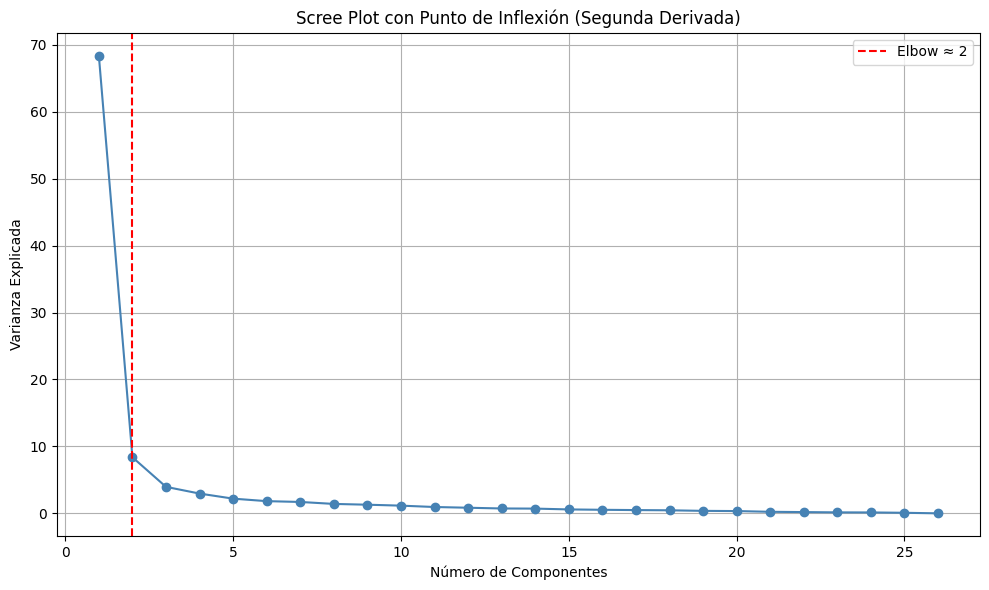

Punto de inflexión sugerido por segunda derivada: 2


In [45]:
# PCA completo
pca_full = PCA()
pca_full.fit(pca_input)

# Varianza explicada
explained_var = pca_full.explained_variance_ratio_

# Segunda derivada
second_derivative = np.diff(explained_var, n=2)
elbow_point = np.argmax(second_derivative) + 2  # +2 para alinear con el número de componentes

# Plot
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(explained_var) + 1), explained_var * 100, marker='o', linestyle='-', color='steelblue')
plt.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada')
plt.title('Scree Plot con Punto de Inflexión (Segunda Derivada)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Imprimir punto de inflexión
print(f"Punto de inflexión sugerido por segunda derivada: {elbow_point}")

In [46]:
pca_2 = PCA(n_components=2)

In [47]:
countries_win6_pca = pca_2.fit_transform(pca_input)

In [48]:
pca_df = pd.DataFrame(countries_win6_pca, columns=['PC1', 'PC2'])

In [49]:
pca_df.head()

,PC1,PC2
0,-3.290166,-0.143972
1,-2.111346,-0.457831
2,-12.586883,1.268163
3,13.749000,3.420537
4,-15.929055,-2.680977


In [50]:
print(pca_2.explained_variance_ratio_)
print(pca_2.explained_variance_ratio_.sum())

[0.68379957 0.08378212]
0.7675816966130973


In [51]:
sum_var_expl_sum = round(float(pca_2.explained_variance_ratio_.sum()),2)

In [52]:
tuple_var_expl_pca = (round(float(pca_2.explained_variance_ratio_[0]),2), round(float(pca_2.explained_variance_ratio_[1]),2))

### Develop Cluster KMeans++
* With elbow method
* With silhouette plot for quality
* Export df with country, iso_a3, cluster category and continent in parquet format, manage missing values before importing

In [53]:
from sklearn.cluster import KMeans

#### final_win_country_delete5

In [54]:
cluster_input5 = pca_df.select_dtypes(include='number')
cluster_input5.head()

,PC1,PC2
0,-3.290166,-0.143972
1,-2.111346,-0.457831
2,-12.586883,1.268163
3,13.749000,3.420537
4,-15.929055,-2.680977


#### Using the elbow method to find the optimal number of clusters

In [55]:
distortions = []

In [56]:
import time

In [57]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


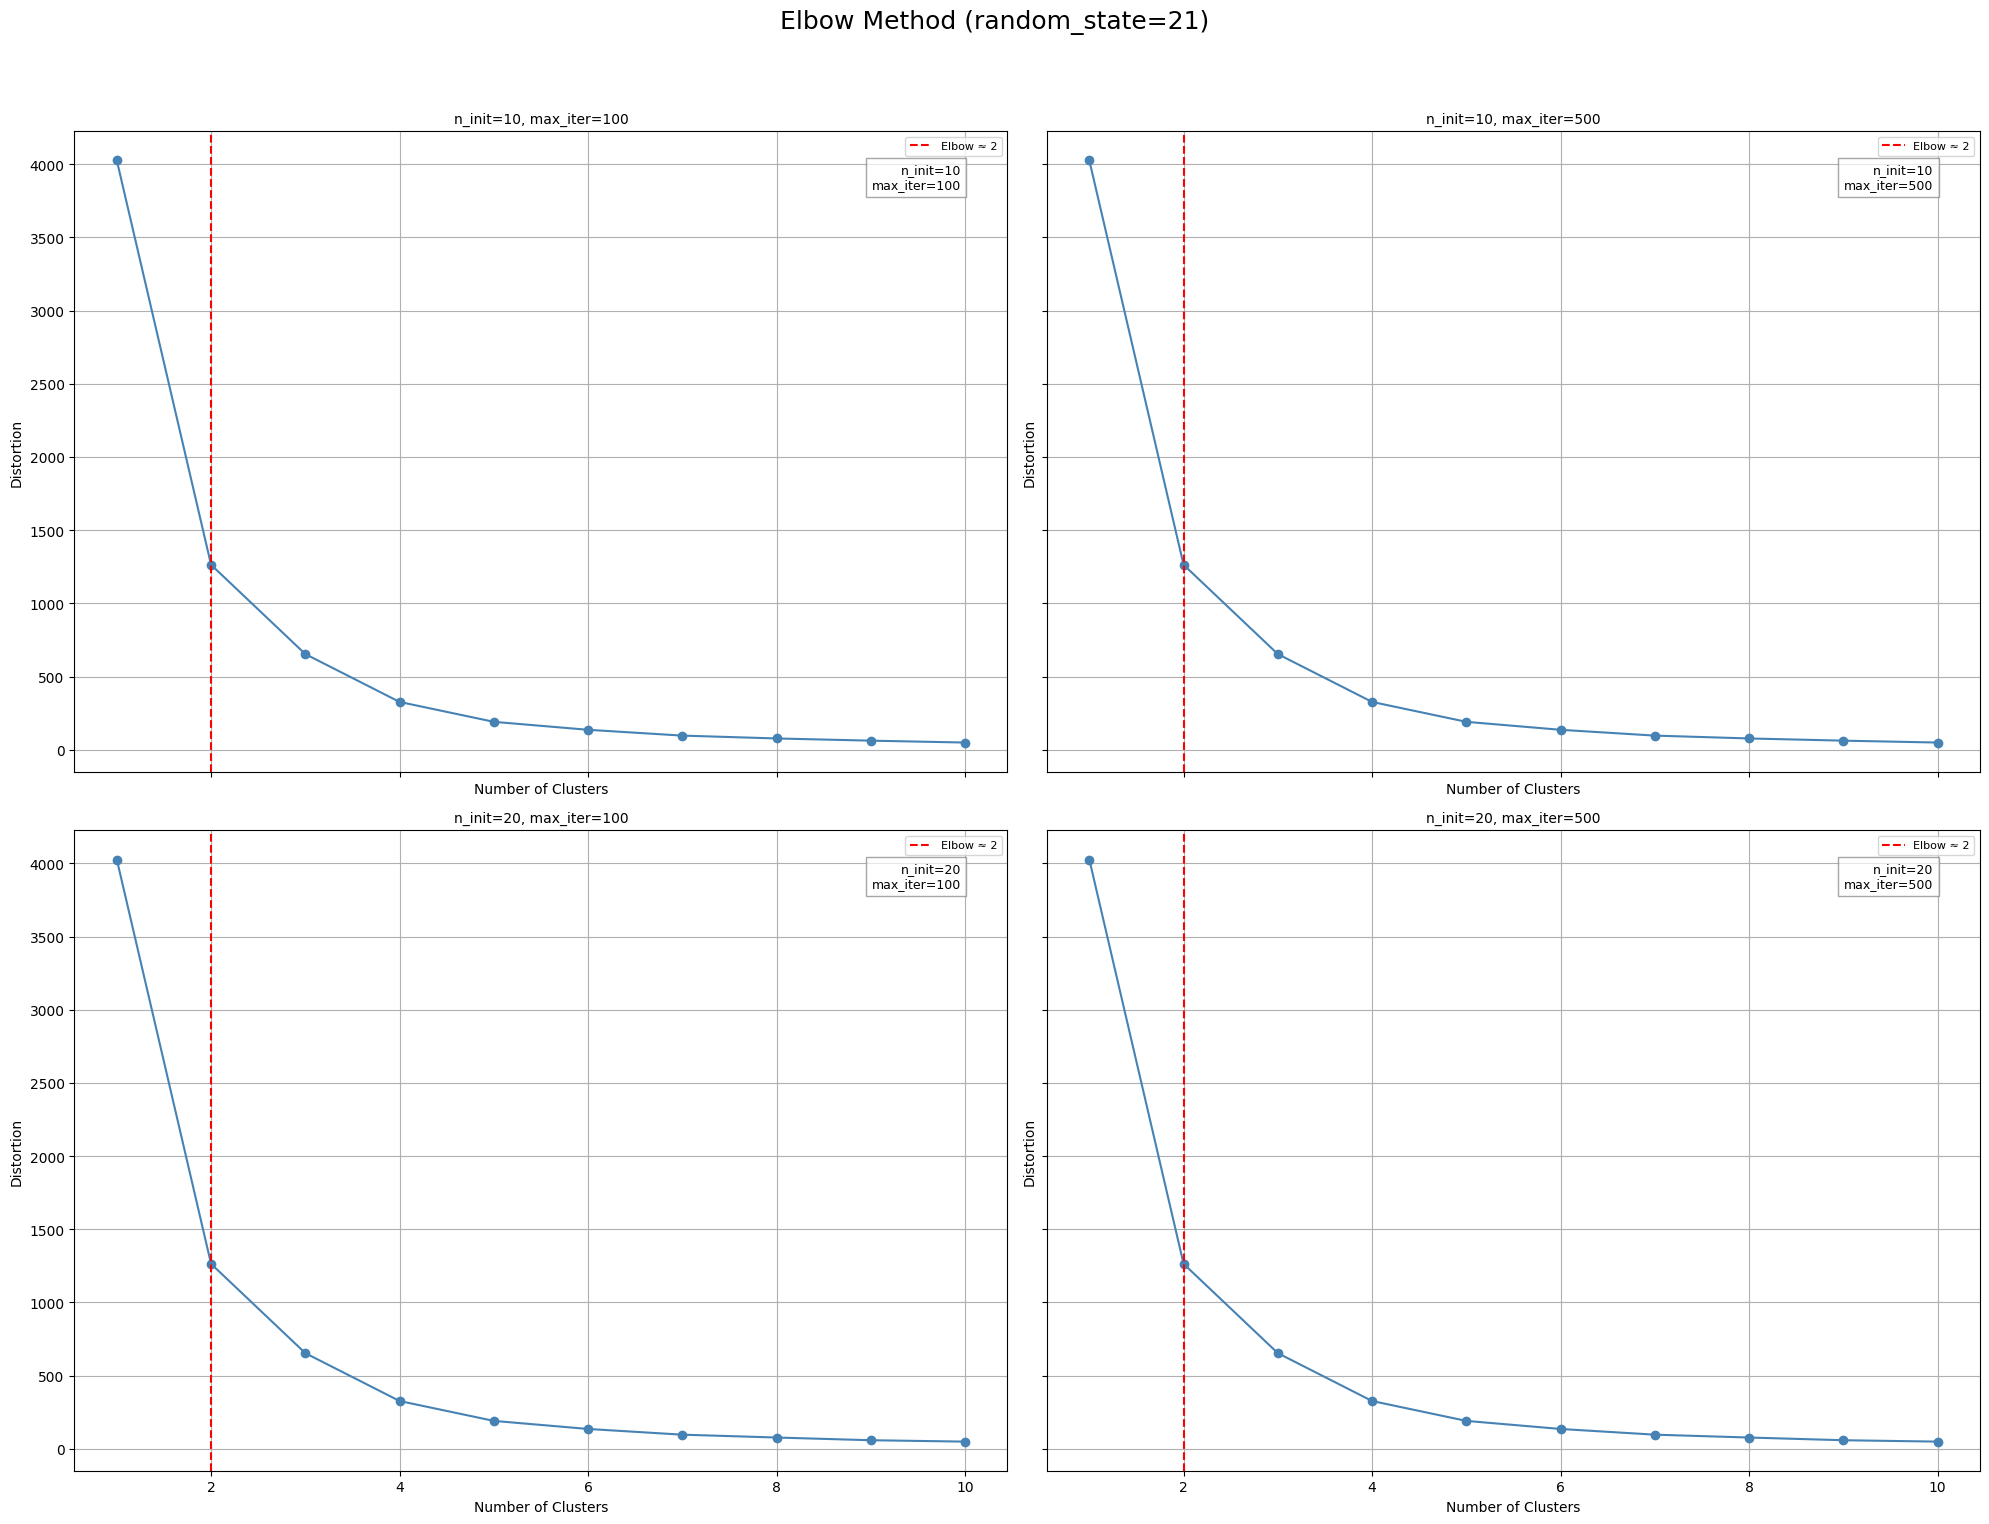


Running elbow plots for random_state=42


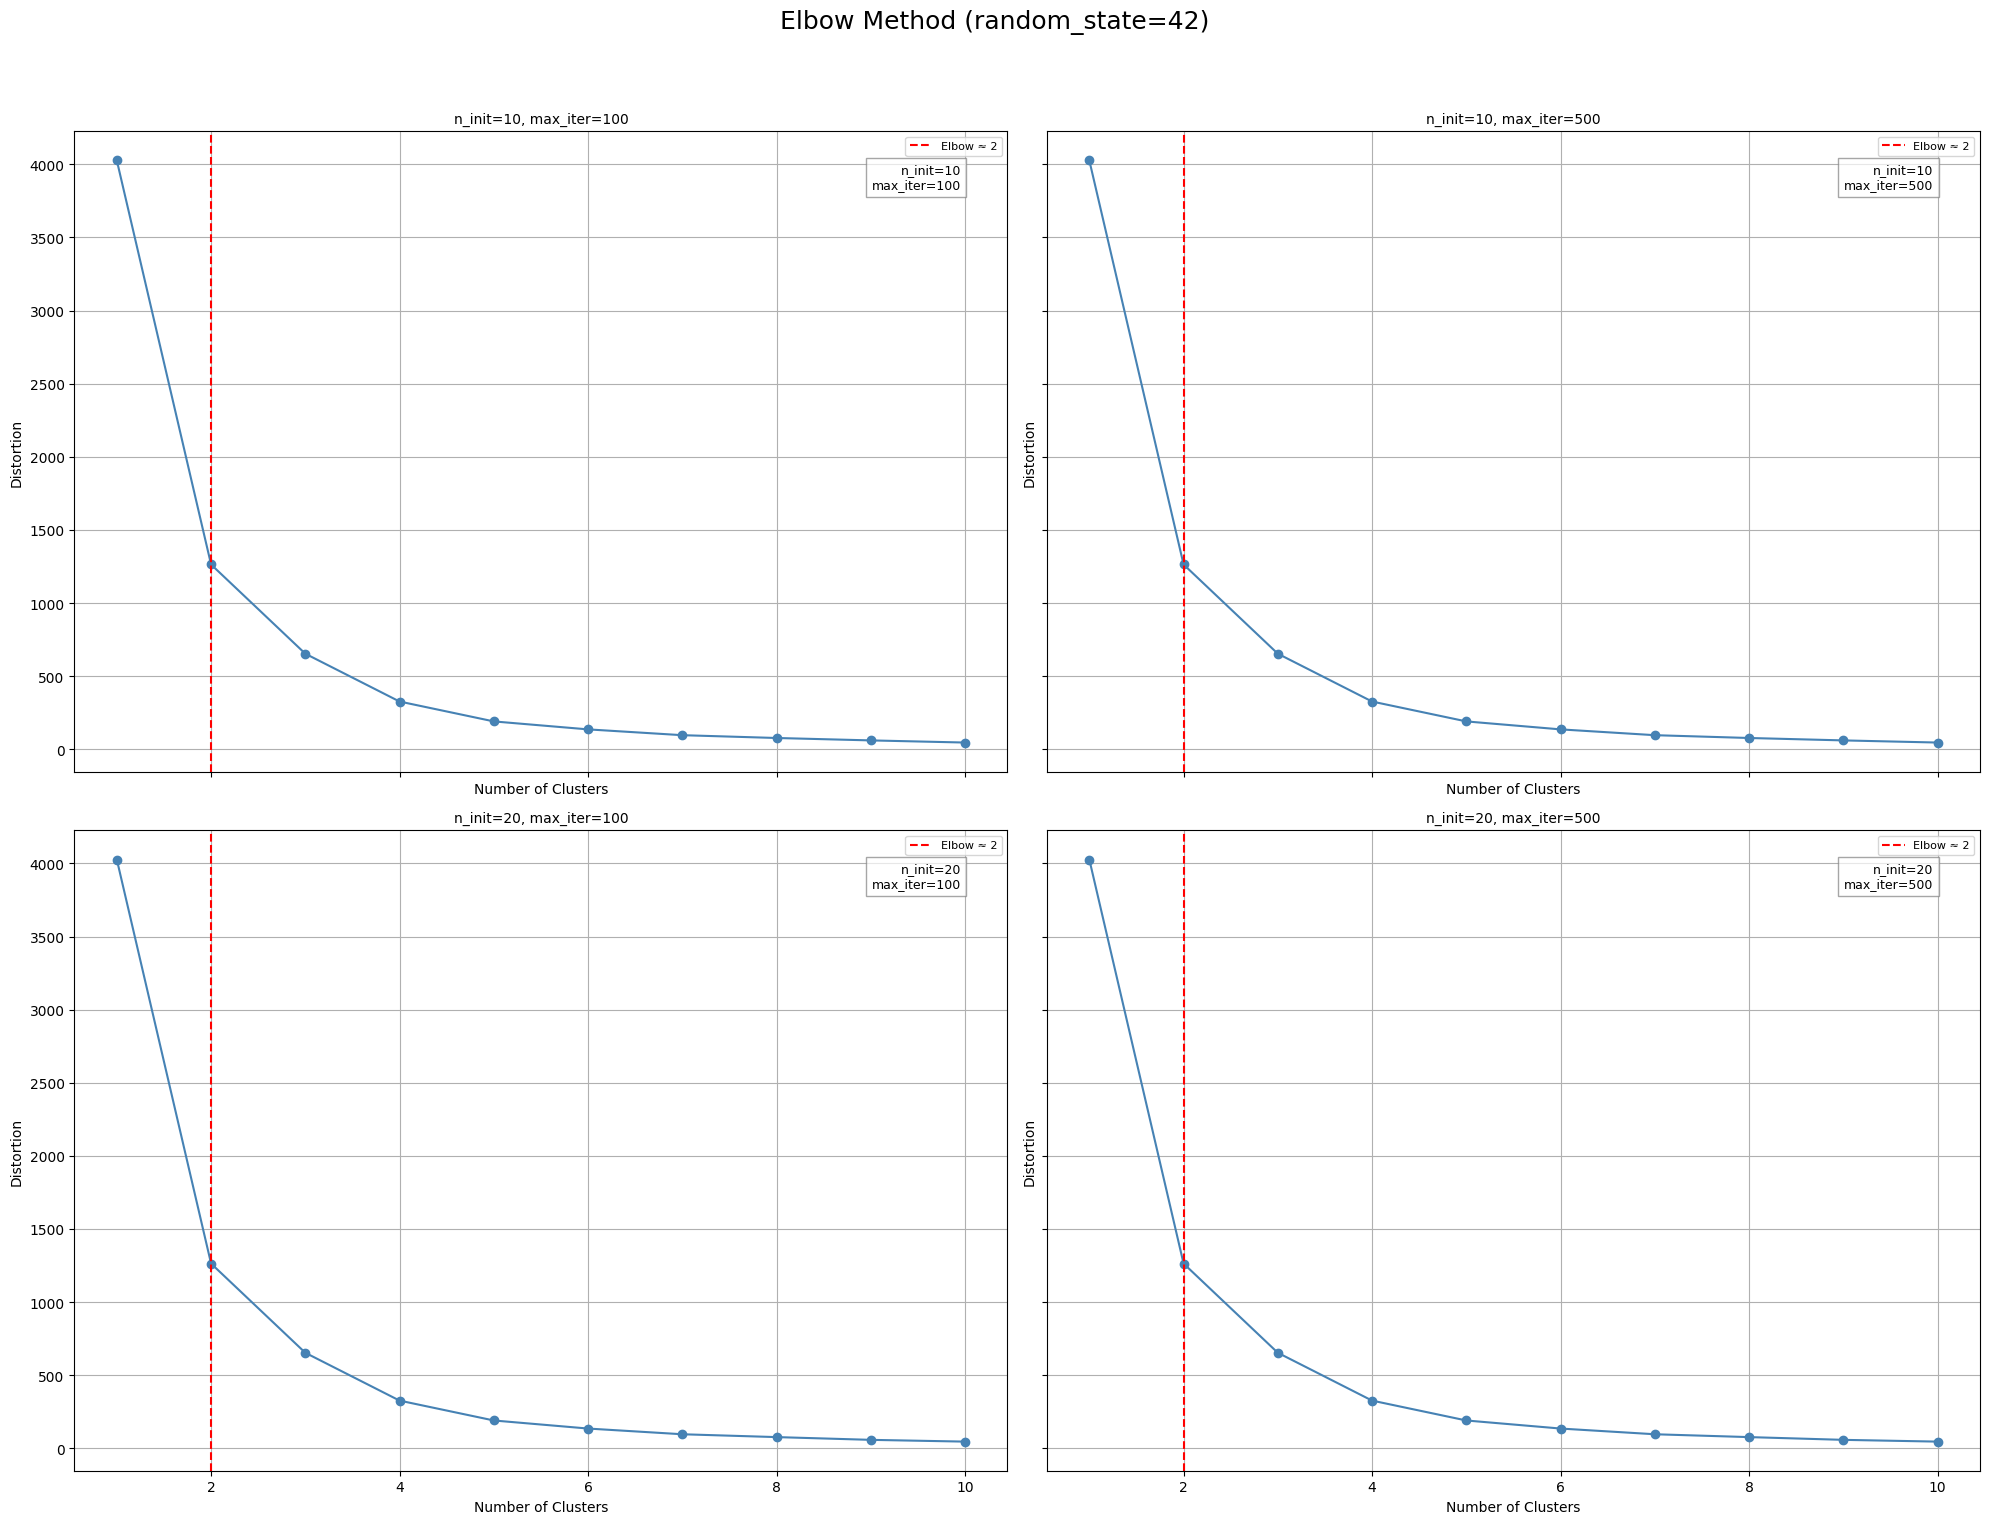


Total execution time: 6.85 seconds


In [58]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input5)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [59]:
from sklearn.metrics import silhouette_samples

In [60]:
from matplotlib import cm

In [61]:
def plot_silhouette(kmeans_model, X):
    """
    Generates a silhouette plot to evaluate the quality of KMeans clustering.

    Parameters:
    - kmeans_model: a fitted KMeans model.
    - X: the input feature matrix used for clustering.

    Returns:
    - silhouette_avg: the average silhouette coefficient across all samples.
    """
    labels = kmeans_model.labels_
    n_clusters = len(np.unique(labels))
    silhouette_vals = silhouette_samples(X, labels, metric='euclidean')
    silhouette_avg = np.mean(silhouette_vals)

    y_ax_lower, yticks = 0, []

    for i in range(n_clusters):
        cluster_vals = silhouette_vals[labels == i]
        cluster_vals.sort()
        y_ax_upper = y_ax_lower + len(cluster_vals)

        color = cm.jet(float(i) / n_clusters)
        plt.barh(
            range(y_ax_lower, y_ax_upper),
            cluster_vals,
            height=1.0,
            edgecolor='none',
            color=color
        )

        yticks.append((y_ax_lower + y_ax_upper) / 2.)
        y_ax_lower = y_ax_upper

    plt.axvline(silhouette_avg, color="red", linestyle="--", label=f"Average: {silhouette_avg:.2f}")
    plt.yticks(yticks, [f'Cluster {i+1}' for i in range(n_clusters)])
    plt.ylabel('Cluster')
    plt.xlabel('Silhouette coefficient')
    plt.title('Silhouette plot by cluster')
    plt.legend()
    plt.tight_layout()
    plt.show()

    return silhouette_avg

In [62]:
km_c2_ni20_maxi500 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [63]:
ym_c2_ni20_maxi500 = km_c2_ni20_maxi500.fit(cluster_input5)

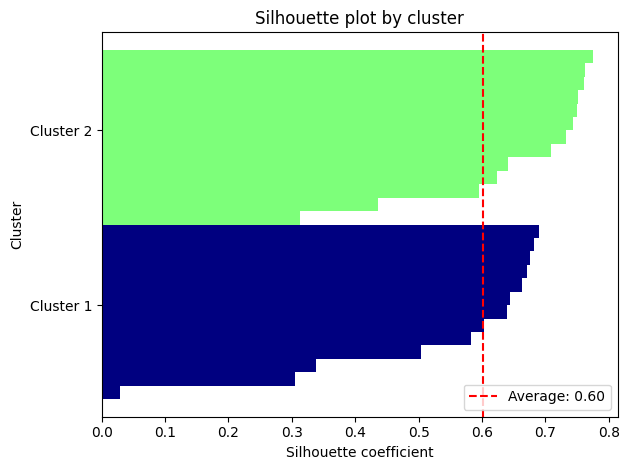

In [64]:
silhoutte_c2_ni20_maxi500 = plot_silhouette(ym_c2_ni20_maxi500, cluster_input5)

In [55]:
np.bincount(ym_c2_ni20_maxi500.labels_)

array([13, 13])

In [56]:
c2_ni20_maxi500_5 = final_win_country_delete5.copy()

In [57]:
c2_ni20_maxi500_5['cluster'] = ym_c2_ni20_maxi500.labels_

In [58]:
import country_converter as coco

In [59]:
c2_ni20_maxi500_5['ISO_A3'] = coco.convert(names=c2_ni20_maxi500_5['Country'], to='ISO3')

In [60]:
clusters_c2_ni20_maxi500_5 = c2_ni20_maxi500_5[['Country', 'ISO_A3', 'cluster']].copy()

In [61]:
clusters_c2_ni20_maxi500_5.loc[:, 'Continent'] = coco.convert(
    names=clusters_c2_ni20_maxi500_5['Country'], to='continent'
)

In [62]:
def print_cluster_groups(df_clusters):
    """
    Groups countries by their cluster and prints each group with country name and continent.

    Parameters:
    - df_clusters: DataFrame containing 'Country', 'cluster', and 'CONTINENT' columns
    """

    # Ensure required columns exist
    required_cols = {'Country', 'cluster', 'Continent'}
    if not required_cols.issubset(df_clusters.columns):
        print("Missing required columns in the DataFrame.")
        return

    # Group countries by cluster
    grouped = df_clusters.groupby('cluster')

    # Print each cluster group
    for cluster_id, group in grouped:
        print(f"\n🌍 Cluster {cluster_id} ({len(group)} countries):")
        for _, row in group.iterrows():
            country = row['Country']
            continent = row['Continent']
            print(f" - {country} ({continent})")

In [63]:
print_cluster_groups(clusters_c2_ni20_maxi500_5)


🌍 Cluster 0 (13 countries):
 - Czech (Europe)
 - France (Europe)
 - Germany (Europe)
 - Iceland (Europe)
 - Italy (Europe)
 - Netherlands (Europe)
 - Norway (Europe)
 - Paraguay (America)
 - Poland (Europe)
 - Spain (Europe)
 - Sweden (Europe)
 - Thailand (Asia)
 - United Kingdom (Europe)

🌍 Cluster 1 (13 countries):
 - Austria (Europe)
 - Belgium (Europe)
 - Croatia (Europe)
 - Estonia (Europe)
 - Finland (Europe)
 - Greece (Europe)
 - Ireland (Europe)
 - Latvia (Europe)
 - Lithuania (Europe)
 - Luxembourg (Europe)
 - Malta (Europe)
 - Portugal (Europe)
 - Slovenia (Europe)


In [64]:
clusters_c2_ni20_maxi500_5['Country'] = clusters_c2_ni20_maxi500_5['Country'].replace('Czech','Czech Republic')

In [114]:
clusters_c2_ni20_maxi500_5

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [115]:
clusters_c2_ni20_maxi500_5.to_parquet('../data/clusters/winner_cluster.parquet')

#### final_win_country_delete6

In [66]:
cluster_input6 = final_win_country_delete6.select_dtypes(include='number')
cluster_input6.head()

,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,livestock_prod_cv,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.554929,4.560173,1.820075,0.054347,...,0.432566,0.422131,-0.489723,0.470588,0.438596,0.444444,0.225607,-0.482700,1.086080,0.386612
1,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,0.011140,...,0.367599,0.368852,-0.187144,0.352941,0.456140,0.251852,-0.098598,-0.237756,1.945877,0.000000
2,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,0.016140,...,0.139803,0.118852,0.356467,0.109244,0.271930,0.037037,-0.488994,1.076138,0.331708,-0.583333
5,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.728184,4.749703,2.044840,0.057789,...,0.518092,0.508197,-0.122864,0.512605,0.640351,0.392593,-0.173826,0.525702,-0.083223,-0.446721
6,2.328545,2.318950,0.359796,2.278292,2.394252,2.394252,4.629277,4.634243,1.343487,0.027274,...,-0.215461,-0.209016,0.737143,-0.302521,-0.157895,-0.200000,-0.188519,-0.729700,0.659211,-0.301913


#### Using the elbow method to find the optimal number of clusters

In [67]:
distortions = []

In [68]:
import time

In [70]:
# Parameters
n_init_list = [10, 20]
max_iter_list = [100, 500]
n_clusters_range = range(1, 11)
random_states = [21, 42]


Running elbow plots for random_state=21


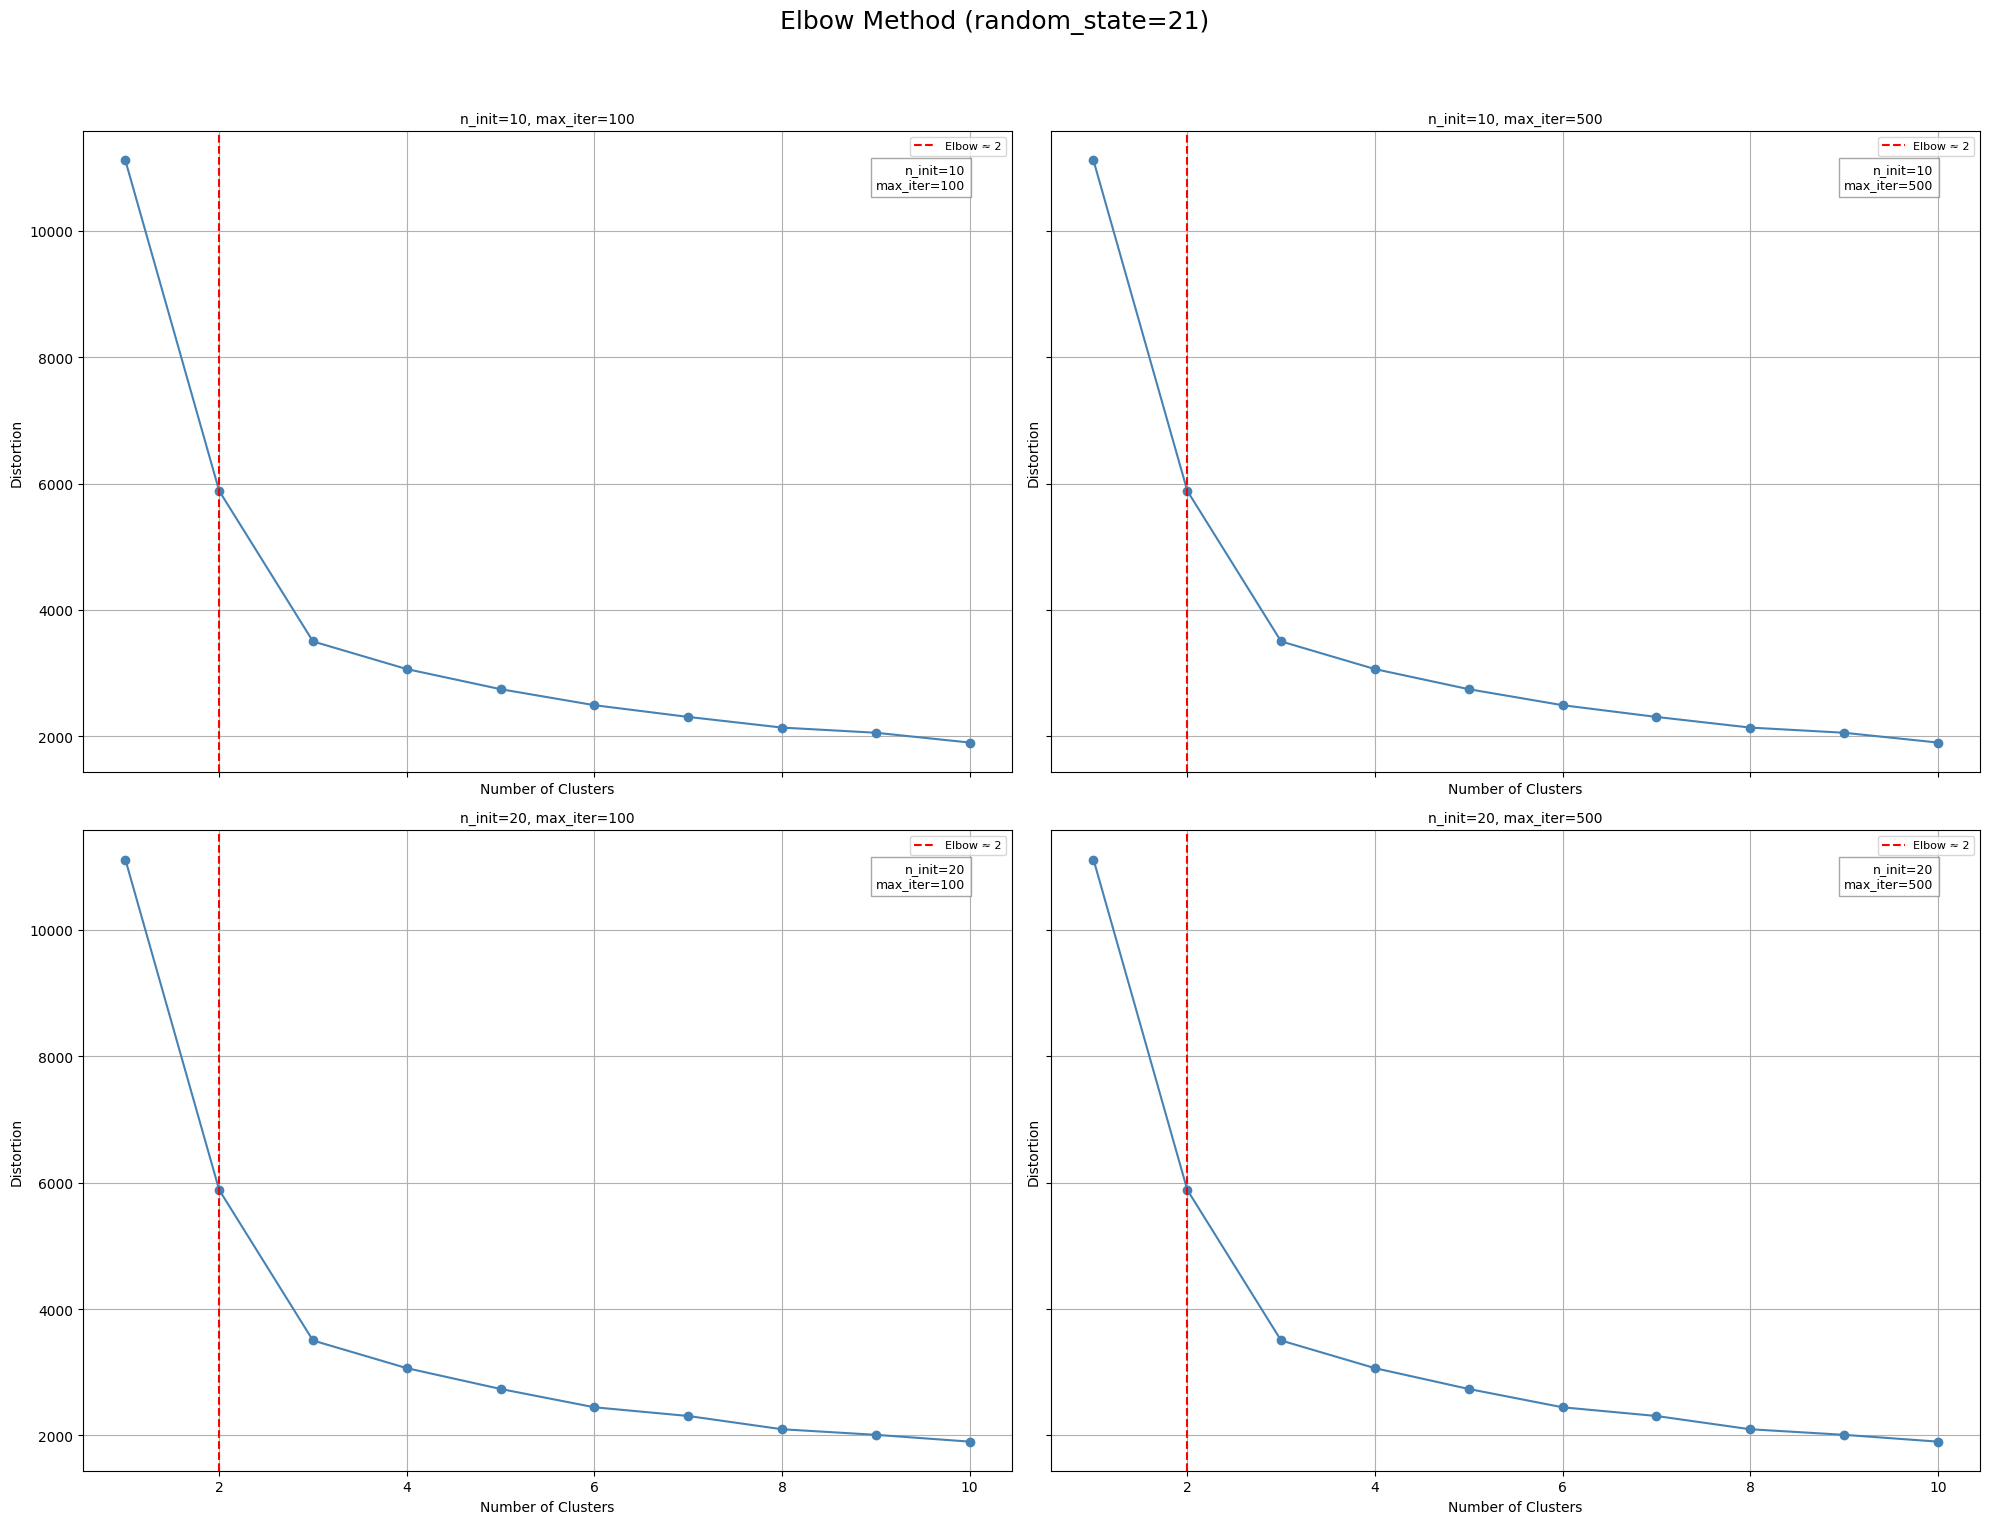


Running elbow plots for random_state=42


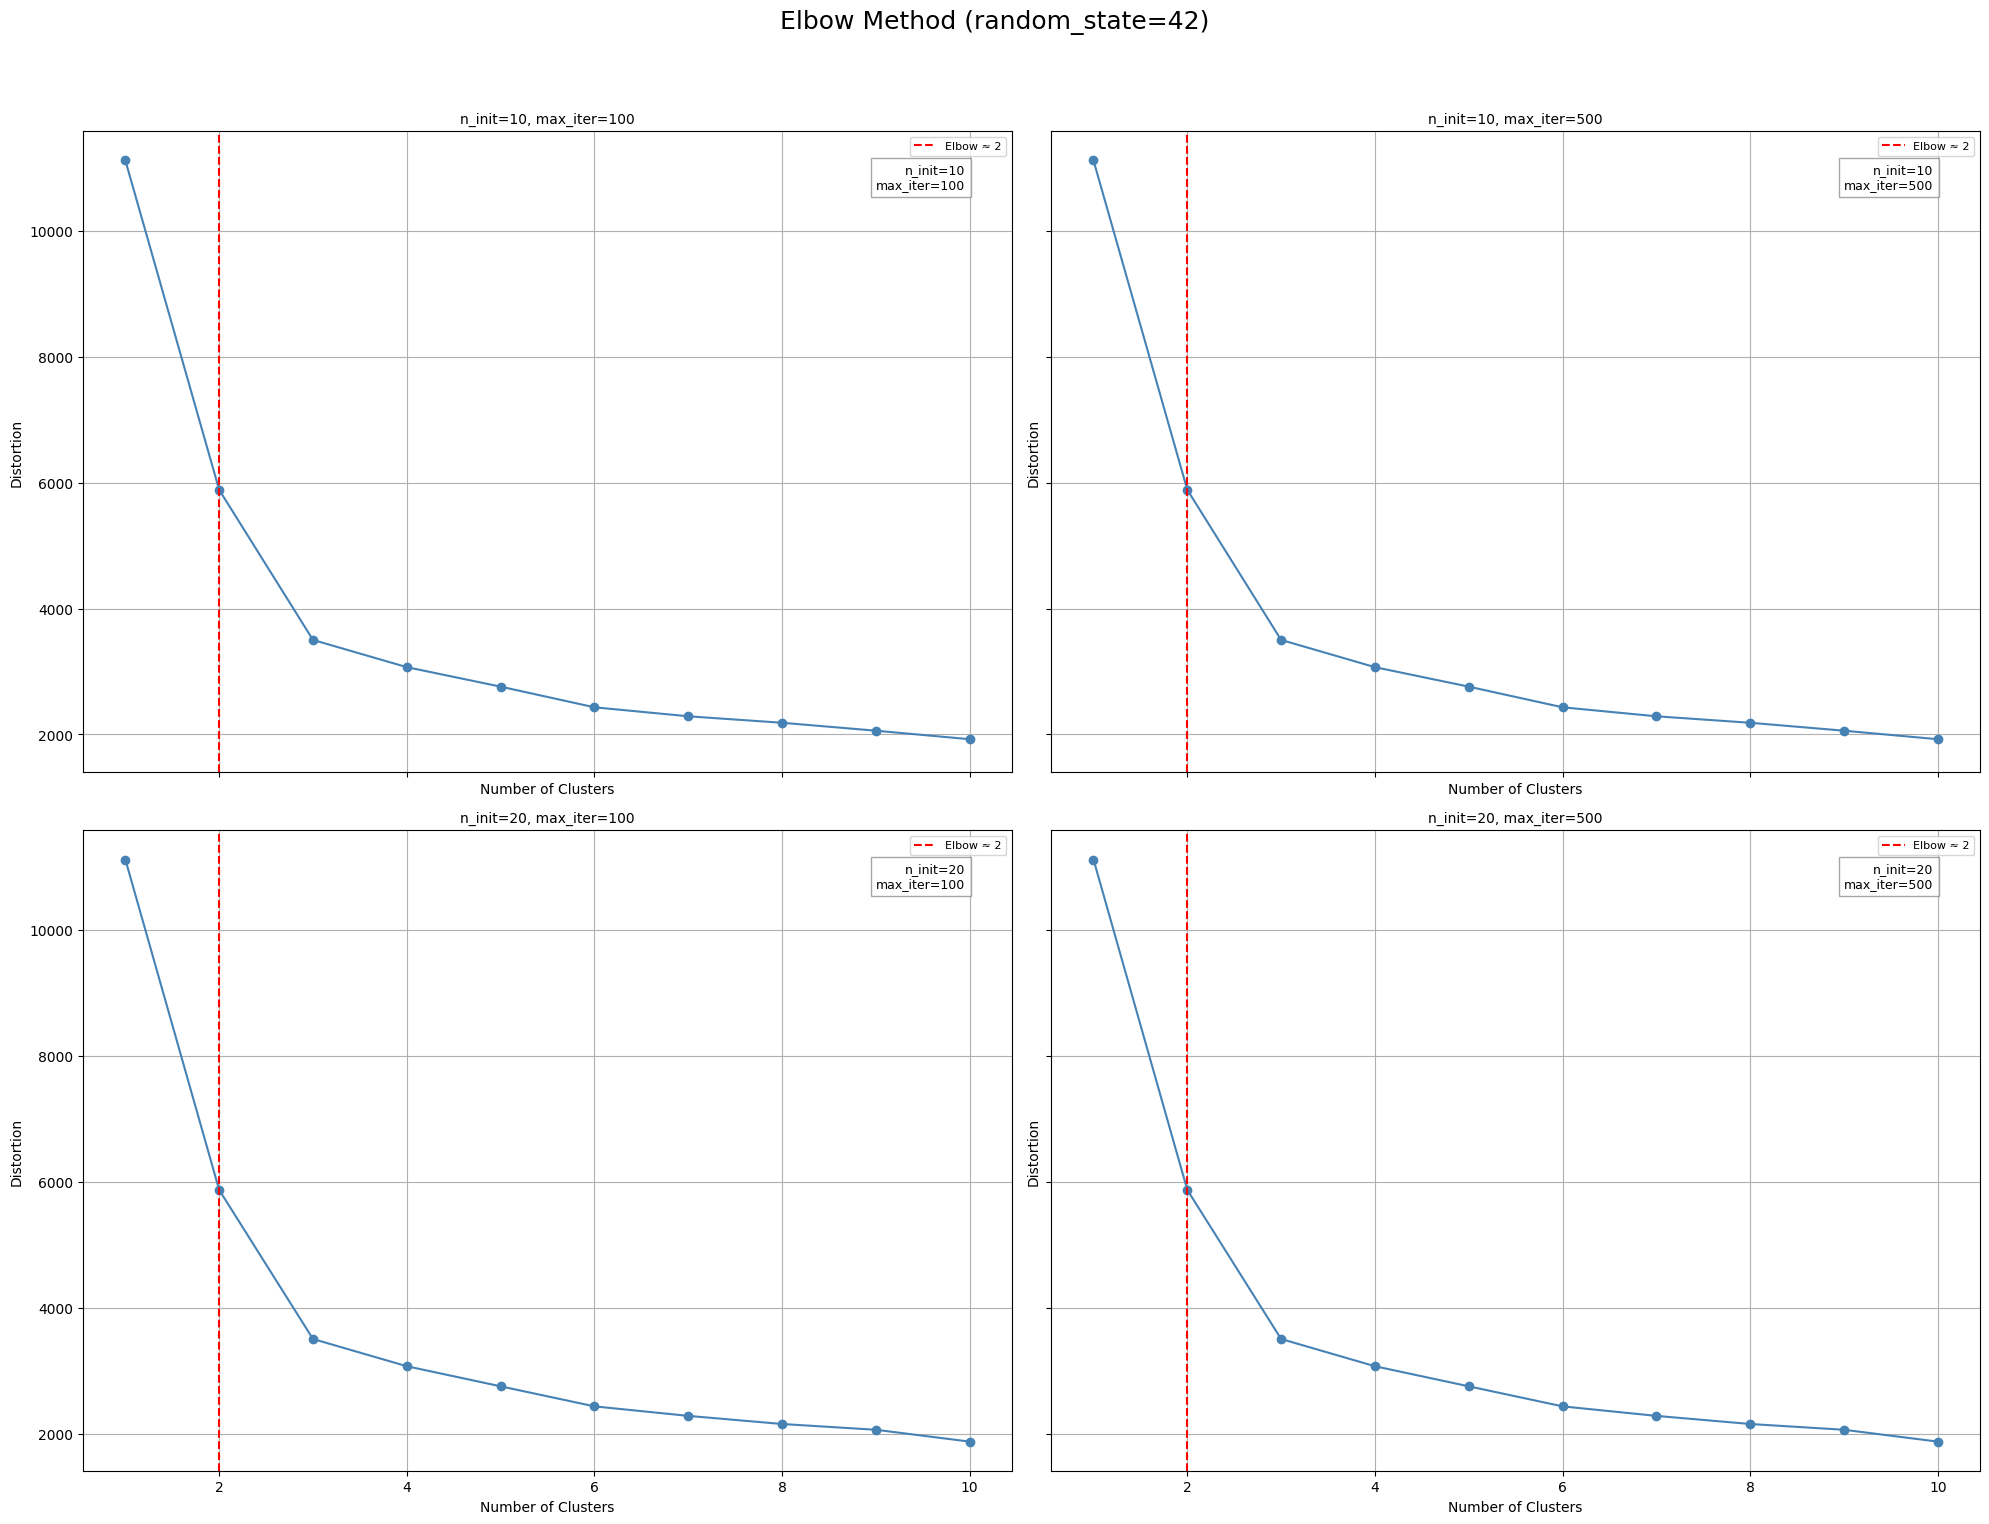


Total execution time: 5.20 seconds


In [71]:
# Start timer
start_time = time.time()

# Iterate over random states
for rs in random_states:
    print(f"\nRunning elbow plots for random_state={rs}")

    # Create figure grid
    fig, axes = plt.subplots(len(n_init_list), len(max_iter_list), figsize=(20, 16), sharex=True, sharey=True)
    fig.suptitle(f'Elbow Method (random_state={rs})', fontsize=18)

    # Iterate over parameter combinations
    for i, n_init in enumerate(n_init_list):
        for j, max_iter in enumerate(max_iter_list):
            distortions = []
            for k in n_clusters_range:
                km = KMeans(
                    n_clusters=k,
                    init='k-means++',
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=rs
                )
                km.fit(cluster_input6)
                distortions.append(km.inertia_)

            # Compute second derivative to find elbow
            second_derivative = np.diff(distortions, n=2)
            elbow_point = np.argmax(second_derivative) + 2  # +2 to align with cluster count

            # Plot
            ax = axes[i, j]
            ax.plot(n_clusters_range, distortions, marker='o', linestyle='-', color='steelblue')
            ax.axvline(x=elbow_point, color='red', linestyle='--', label=f'Elbow ≈ {elbow_point}')
            ax.set_title(f'n_init={n_init}, max_iter={max_iter}', fontsize=10)
            ax.set_xlabel('Number of Clusters')
            ax.set_ylabel('Distortion')
            ax.grid(True)
            ax.legend(loc='upper right', fontsize=8)

            # Annotate parameters inside plot
            ax.text(
                0.95, 0.95,
                f'n_init={n_init}\nmax_iter={max_iter}',
                transform=ax.transAxes,
                fontsize=9,
                verticalalignment='top',
                horizontalalignment='right',
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='gray')
            )

    # Final layout and display
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# End timer
end_time = time.time()
print(f"\nTotal execution time: {end_time - start_time:.2f} seconds")

* So the distorsion is less that the previous cluster model
* See what about the silhouette

#### Quantifying the quality of clustering via silhouette plots

The previous code was a nonsense since each iteration found the same elbow, so we will see if each iteration with a different hyperparameter results in a cluster with different members.

The code for each model will be as follows:
- cx = where c corresponds to 'clusters' and x corresponds to the number of clusters used
- nix = where ni corresponds to 'n_init' and x to the number of initializations used
- maxix = where maxi corresponds to 'max_iter' and x to the number of maximum iterations selected

In [69]:
km_c2_ni20_maxi500_6 = KMeans(n_clusters=2,
            init='k-means++',
            n_init=20,
            max_iter=500,
            random_state=42)

In [70]:
ym_c2_ni20_maxi500_6 = km_c2_ni20_maxi500_6.fit(cluster_input6)

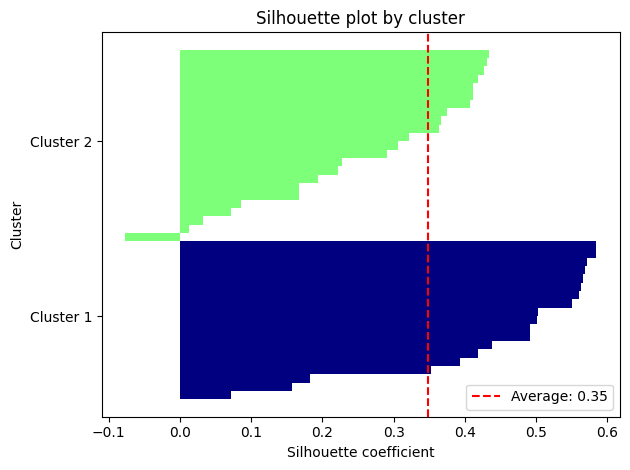

In [71]:
silhoutte_c2_ni20_maxi500_6 = plot_silhouette(ym_c2_ni20_maxi500_6, cluster_input6)

* Bad results

### Import and clean data for create synthetic data
* Import the data for hpi by country
* Observe if have Pararguay country
* Look if have the same countries that the df with the culsters
* Look if the name of the countries are in the same format "-" or "_"
* Delete countries that do not exist in the HPI dataframe

In [72]:
df_hpi_winsorized = pd.read_parquet('../data/hpi_index_winsorized.parquet')

In [73]:
df_hpi_winsorized.shape

(15, 53)

In [74]:
clusters_c2_ni20_maxi500_5.shape

(26, 4)

In [75]:
def find_countries_missing_from_clusters(df_hpi, df_clusters, country_column='Country'):
    """
    Identifies which countries are present in the HPI DataFrame but missing from the cluster DataFrame.

    Parameters:
    - df_hpi: DataFrame where columns are country names and rows are years (House Price Index data)
    - df_clusters: DataFrame with country names and cluster assignments
    - country_column: Name of the column in df_clusters that contains country names (default: 'Country')

    Returns:
    - List of country names that are in df_hpi but not in df_clusters
    """

    # Extract country names from HPI DataFrame (column headers)
    hpi_countries = set(df_hpi.columns)

    # Extract country names from cluster DataFrame
    cluster_countries = set(df_clusters[country_column].unique())

    # Find countries present in HPI but missing from clusters
    missing_countries = hpi_countries - cluster_countries

    # Print results
    if missing_countries:
        print("Countries in HPI that are missing from the cluster DataFrame:")
        for country in sorted(missing_countries):
            print(f" - {country}")
    else:
        print("All countries in the HPI DataFrame are present in the cluster DataFrame.")

    return list(missing_countries)

In [76]:
missing_countries_5 = find_countries_missing_from_clusters(df_hpi_winsorized, clusters_c2_ni20_maxi500_5)

Countries in HPI that are missing from the cluster DataFrame:
 - Australia
 - Brazil
 - Bulgaria
 - Canada
 - Chile
 - Colombia
 - Cyprus
 - Denmark
 - Hungary
 - India
 - Israel
 - Japan
 - Malaysia
 - Mexico
 - New Zealand
 - Peru
 - Philippines
 - Romania
 - Russia
 - Serbia
 - Singapore
 - Slovakia
 - South Africa
 - South Korea
 - Switzerland
 - Turkey
 - USA
 - Year


In [77]:
df_hpi_winsorized.head()

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,Colombia,Croatia,...,Slovenia,South Africa,South Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United Kingdom
0,2010,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,...,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
1,2011,97.84,104.22,103.58,110.52,94.49,105.75,110.52,107.89,100.16,...,102.72,103.59,105.23,94.49,102.58,107.51,104.26,108.80,97.24,98.54
2,2012,97.53,117.13,106.02,124.02,92.69,110.62,124.02,118.79,98.62,...,95.63,108.41,108.25,88.37,103.86,113.72,107.63,120.68,101.82,98.92
3,2013,103.99,122.59,107.59,136.52,90.65,112.76,136.52,130.06,94.70,...,90.62,115.41,107.80,85.58,109.22,118.30,115.99,134.46,111.83,101.46
4,2014,113.41,126.79,107.22,151.67,91.95,118.86,151.67,140.75,93.19,...,84.64,123.99,109.43,84.64,119.52,121.46,127.07,151.25,118.88,109.60


In [78]:
def drop_country_columns_except_year(df, country_list, year_label="Year"):
    """
    Elimina columnas del DataFrame que coincidan con los nombres en 'country_list',
    ignorando la columna 'Year' incluso si está en la lista.

    Parámetros:
    - df: pandas.DataFrame
        DataFrame original con columnas nombradas por país.
    - country_list: list
        Lista de nombres de países (y posiblemente 'Year').
    - year_label: str
        Nombre de la columna que debe conservarse aunque esté en la lista.

    Retorna:
    - df_filtrado: pandas.DataFrame
        DataFrame sin las columnas correspondientes a los países (excepto 'Year').
    """

    # Filtrar la lista excluyendo 'Year'
    columns_to_drop = [col for col in country_list if col != year_label]

    # Eliminar columnas si existen en el DataFrame
    df_filtrado = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

    print(f"Columnas eliminadas: {columns_to_drop}")
    return df_filtrado

In [79]:
hpi_c2_ni20_maxi500_5 = drop_country_columns_except_year(df_hpi_winsorized, missing_countries_5)

Columnas eliminadas: ['Turkey', 'Peru', 'Philippines', 'India', 'South Korea', 'Japan', 'Singapore', 'Bulgaria', 'Slovakia', 'South Africa', 'USA', 'Chile', 'Cyprus', 'Israel', 'New Zealand', 'Romania', 'Colombia', 'Canada', 'Mexico', 'Australia', 'Switzerland', 'Brazil', 'Denmark', 'Russia', 'Serbia', 'Malaysia', 'Hungary']


In [80]:
find_countries_missing_from_clusters(hpi_c2_ni20_maxi500_5, clusters_c2_ni20_maxi500_5)

Countries in HPI that are missing from the cluster DataFrame:
 - Year


['Year']

In [81]:
hpi_c2_ni20_maxi500_5.shape

(15, 26)

### Apply transformation over hpi index
* Apply winsorization
* Apply round to two decimal
* Plot boxplot for every year

In [82]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Figure size 1400x600 with 0 Axes>

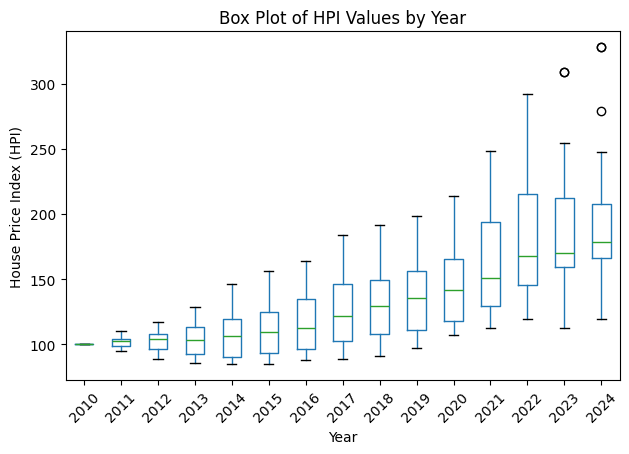

In [83]:
plot_hpi_boxplots_by_year(hpi_c2_ni20_maxi500_5)

In [84]:
def round_and_winsorize_hpi(df_hpi, year_column='Year', limits=(0.05, 0.05)):
    """
    Rounds all HPI values to two decimals, then applies Winsorization per year.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - limits: Tuple indicating proportion to cut from each tail (default: 10%)

    Returns:
    - DataFrame with rounded and Winsorized HPI values
    """

    # Step 1: Round all numeric values to 2 decimals
    df_rounded = df_hpi.copy()
    country_columns = [col for col in df_rounded.columns if col != year_column]
    df_rounded[country_columns] = df_rounded[country_columns].round(2)

    # Step 2: Apply Winsorization row by row
    df_winsorized = df_rounded.copy()

    for idx, row in df_rounded.iterrows():
        values = row[country_columns].values.astype(float)

        # Apply Winsorization only if enough valid values
        if np.count_nonzero(~np.isnan(values)) >= 4:
            winsorized = winsorize(values, limits=limits)
            df_winsorized.loc[idx, country_columns] = winsorized

    return df_winsorized

In [85]:
hpi_c2_ni20_maxi500_5_win = round_and_winsorize_hpi(hpi_c2_ni20_maxi500_5, limits=(0.08,0.08))

<Figure size 1400x600 with 0 Axes>

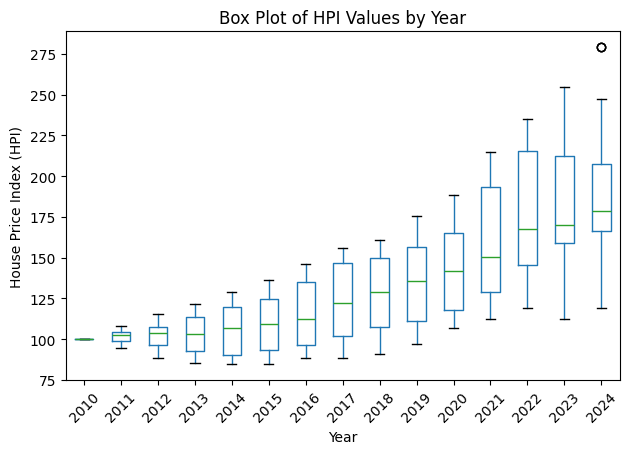

In [86]:
plot_hpi_boxplots_by_year(hpi_c2_ni20_maxi500_5_win)

In [87]:
hpi_c2_ni20_maxi500_5_win1 = round_and_winsorize_hpi(hpi_c2_ni20_maxi500_5_win, limits=(0.12,0.12))

<Figure size 1400x600 with 0 Axes>

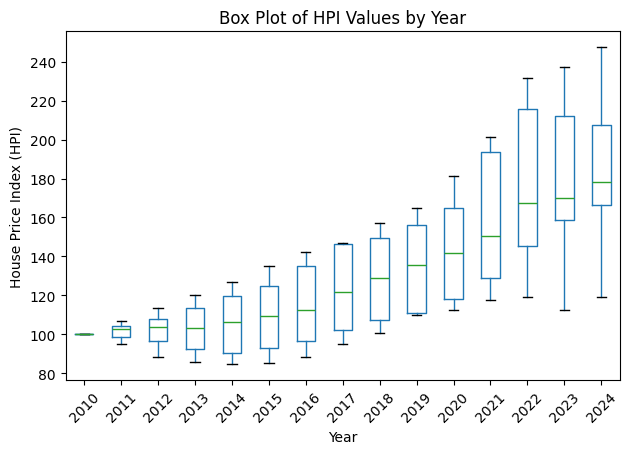

In [88]:
plot_hpi_boxplots_by_year(hpi_c2_ni20_maxi500_5_win1)

### Leverage The Law of Large Numbers
* Run the sampling process for each cluster, exclude one country of that cluster to compare

In [89]:
import random

In [90]:
def evaluate_cluster_sampling_errors(df_hpi, df_clusters, cluster_id,
                                     cluster_column='cluster', country_column='Country',
                                     year_column='Year', sample_size=30, n_samples=1000,
                                     plot=True, seed=None):
    """
    Evaluates synthetic HPI estimation via bootstrap sampling for each country in a cluster.

    Returns:
    - avg_mse: Average MSE across all countries in the cluster
    - avg_mae: Average MAE across all countries in the cluster
    - best_country: Country with the lowest MSE
    - yearly_bootstrap_means: Dict with year as key and synthetic mean using best_country as excluded
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    all_cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in all_cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) < 2:
        raise ValueError("Cluster must contain at least two countries present in HPI data.")

    mse_scores = {}
    mae_scores = {}

    for excluded_country in cluster_countries:
        sampling_countries = [c for c in cluster_countries if c != excluded_country]
        synthetic_values = []
        actual_values = []

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(excluded_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            synthetic_mean = np.mean(sample_means)

            synthetic_values.append(synthetic_mean)
            actual_values.append(actual_value)

        if len(synthetic_values) == 0:
            mse_scores[excluded_country] = np.nan
            mae_scores[excluded_country] = np.nan
        else:
            errors = np.array(synthetic_values) - np.array(actual_values)
            mse_scores[excluded_country] = np.mean(errors ** 2)
            mae_scores[excluded_country] = np.mean(np.abs(errors))

    best_country = min(mse_scores, key=lambda k: mse_scores[k] if not np.isnan(mse_scores[k]) else np.inf)

    # Plot for best country
    if plot:
        synthetic_values = []
        actual_values = []
        years = []

        sampling_countries = [c for c in cluster_countries if c != best_country]

        for _, row in df_hpi.iterrows():
            year = row[year_column]
            values = row[sampling_countries].dropna().values
            actual_value = row.get(best_country, np.nan)

            if len(values) == 0 or np.isnan(actual_value):
                continue

            sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                            for _ in range(n_samples)]
            cumulative_means = [np.mean(sample_means[:j+1]) for j in range(n_samples)]

            lower_bound = np.percentile(sample_means, 2.5)
            upper_bound = np.percentile(sample_means, 97.5)

            fig, axes = plt.subplots(1, 2, figsize=(14, 4))

            axes[0].hist(sample_means, bins=30, color='lightgreen', edgecolor='black')
            axes[0].axvline(actual_value, color='red', linestyle='--', label=f"Actual: {best_country}")
            axes[0].axvline(lower_bound, color='blue', linestyle=':', label='95% CI Lower')
            axes[0].axvline(upper_bound, color='blue', linestyle=':', label='95% CI Upper')
            axes[0].set_title(f"HPI Sampling Distribution - Year {year}")
            axes[0].set_xlabel("Sample Mean HPI")
            axes[0].set_ylabel("Frequency")
            axes[0].legend()
            axes[0].grid(True)

            axes[1].plot(cumulative_means, color='purple')
            axes[1].axhline(np.mean(sample_means), color='gray', linestyle='--', label='Final Mean')
            axes[1].set_title("Mean Convergence Over Iterations")
            axes[1].set_xlabel("Iteration")
            axes[1].set_ylabel("Cumulative Mean")
            axes[1].legend()
            axes[1].grid(True)

            plt.tight_layout()
            plt.show()

    # Synthetic mean per year using best_country as excluded
    yearly_bootstrap_means = {}
    sampling_countries = [c for c in cluster_countries if c != best_country]

    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[sampling_countries].dropna().values

        if len(values) == 0:
            continue

        sample_means = [np.mean(np.random.choice(values, size=sample_size, replace=True))
                        for _ in range(n_samples)]
        synthetic_mean = np.mean(sample_means)
        yearly_bootstrap_means[year] = synthetic_mean

    # Real mean per year using all countries in the cluster
    yearly_mean = {}
    for _, row in df_hpi.iterrows():
        year = row[year_column]
        values = row[cluster_countries].dropna().values

        if len(values) == 0:
            continue

        yearly_mean[year] = np.mean(values)

    avg_mse = np.nanmean(list(mse_scores.values()))
    avg_mae = np.nanmean(list(mae_scores.values()))

    return avg_mse, avg_mae, best_country, yearly_bootstrap_means, yearly_mean

In [91]:
def calculate_hpi_variance_by_cluster(df_hpi, df_clusters,
                                      cluster_column='cluster', country_column='Country',
                                      year_column='Year'):
    """
    Calculates average HPI variance across countries for each cluster.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values

    Returns:
    - cluster_variances: dict with cluster_id as key and average variance as value
    """
    cluster_variances = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Get countries in this cluster that are present in HPI data
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_variances[cluster_id] = np.nan
            continue

        # Extract HPI values for cluster countries
        hpi_values = df_hpi[cluster_countries]

        # Calculate variance across countries for each year
        yearly_variances = hpi_values.var(axis=1, skipna=True)

        # Compute average variance across all years
        avg_variance = yearly_variances.mean()
        cluster_variances[cluster_id] = avg_variance

    return cluster_variances

In [92]:
def plot_cluster_hpi_with_bootstrap(df_hpi, df_clusters, cluster_id,
                                    yearly_bootstrap_means,
                                    yearly_mean,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots HPI values for each country in a cluster over time,
    along with the synthetic bootstrap mean per year and the actual cluster mean.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_id: Cluster number to plot
    - yearly_bootstrap_means: Dict with year as key and synthetic mean value
    - yearly_mean: Dict with year as key and actual mean HPI of all countries in the cluster
    """
    # Obtener países del cluster
    cluster_countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
    cluster_countries = [c for c in cluster_countries if c in df_hpi.columns]

    if len(cluster_countries) == 0:
        raise ValueError("No hay países válidos en el cluster para graficar.")

    # Graficar HPI real por país
    plt.figure(figsize=(12, 6))
    for country in cluster_countries:
        country_data = df_hpi[[year_column, country]].dropna()
        plt.plot(country_data[year_column], country_data[country], label=country, alpha=0.6)

    # Graficar curva sintética del bootstrap
    bootstrap_years = sorted(yearly_bootstrap_means.keys())
    bootstrap_values = [yearly_bootstrap_means[year] for year in bootstrap_years]
    plt.plot(bootstrap_years, bootstrap_values, label='Bootstrap Mean', color='black', linewidth=2.5)

    # Graficar media real del cluster (línea discontinua)
    mean_years = sorted(yearly_mean.keys())
    mean_values = [yearly_mean[year] for year in mean_years]
    plt.plot(mean_years, mean_values, label='Real Cluster Mean', color='gray', linestyle='--', linewidth=2.5)

    # Estética del gráfico
    plt.title(f"HPI por País en Cluster {cluster_id} + Medias Sintéticas y Reales")
    plt.xlabel("Año")
    plt.ylabel("Índice HPI")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [93]:
def percentage_points_within_iqr_by_cluster(df_hpi, df_clusters,
                                            cluster_column='cluster', country_column='Country',
                                            year_column='Year'):
    """
    Calcula el porcentaje de puntos de HPI que están dentro del IQR (Q1–Q3) por cluster.

    Returns:
    - dict con cluster_id como clave y porcentaje de puntos dentro del IQR como valor
    """
    cluster_iqr_percentages = {}

    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        # Obtener países del cluster presentes en df_hpi
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            cluster_iqr_percentages[cluster_id] = 0.0
            continue

        # Extraer valores de HPI para esos países
        hpi_values = df_hpi[cluster_countries]

        total_within_iqr = 0
        total_values = 0

        # Iterar por año
        for _, row in hpi_values.iterrows():
            values = row.dropna().values
            if len(values) < 2:
                continue

            q1 = np.percentile(values, 25)
            q3 = np.percentile(values, 75)

            # Contar cuántos valores están dentro del IQR
            count_within_iqr = np.sum((values >= q1) & (values <= q3))
            total_within_iqr += count_within_iqr
            total_values += len(values)

        # Calcular porcentaje
        percentage = (total_within_iqr / total_values * 100) if total_values > 0 else 0.0
        cluster_iqr_percentages[cluster_id] = round(percentage, 2)

    return cluster_iqr_percentages


In [94]:
def plot_hpi_boxplots_by_year(df_hpi, year_column='Year', figsize=(14, 6)):
    """
    Plots box plots of HPI values for each year to visualize outliers.

    Parameters:
    - df_hpi: DataFrame with 'Year' column and HPI values per country
    - year_column: Name of the column containing years (default: 'Year')
    - figsize: Size of the plot (default: (14, 6))
    """

    # Step 1: Melt the DataFrame to long format
    df_long = df_hpi.melt(id_vars=year_column, var_name='Country', value_name='HPI')

    # Step 2: Create boxplot grouped by year
    plt.figure(figsize=figsize)
    df_long.boxplot(column='HPI', by=year_column, grid=False, showfliers=True)

    # Step 3: Customize plot
    plt.title("Box Plot of HPI Values by Year")
    plt.suptitle("")  # Remove default title
    plt.xlabel("Year")
    plt.ylabel("House Price Index (HPI)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [95]:
def plot_hpi_dispersion_by_cluster(df_hpi, df_clusters,
                                    cluster_column='cluster', country_column='Country',
                                    year_column='Year'):
    """
    Plots the dispersion of HPI values for each cluster using boxplots.

    Parameters:
    - df_hpi: DataFrame with HPI values (columns = countries, rows = years, plus 'Year' column)
    - df_clusters: DataFrame with country names and cluster assignments
    - cluster_column: Column name in df_clusters with cluster labels
    - country_column: Column name in df_clusters with country names
    - year_column: Column name in df_hpi with year values
    """
    # Crear lista para almacenar datos
    records = []

    # Iterar sobre cada cluster
    for cluster_id in sorted(df_clusters[cluster_column].unique()):
        countries = df_clusters[df_clusters[cluster_column] == cluster_id][country_column].tolist()
        cluster_countries = [c for c in countries if c in df_hpi.columns]

        if len(cluster_countries) < 2:
            continue

        # Extraer valores de HPI por país y año
        for _, row in df_hpi.iterrows():
            year = row[year_column]
            for country in cluster_countries:
                value = row.get(country, np.nan)
                if not np.isnan(value):
                    records.append({
                        'Cluster': f'Cluster {cluster_id}',
                        'Country': country,
                        'Year': year,
                        'HPI': value
                    })

    # Convertir a DataFrame
    df_plot = pd.DataFrame(records)

    # Crear boxplot
    plt.figure(figsize=(12, 6))
    sns.boxplot(hue='Cluster', y='HPI', data=df_plot, palette='Set2', x='Cluster')
    plt.title('HPI Dispersion by Cluster')
    plt.ylabel('Human Potential Index (HPI)')
    plt.xlabel('Cluster')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

### Experiment c2

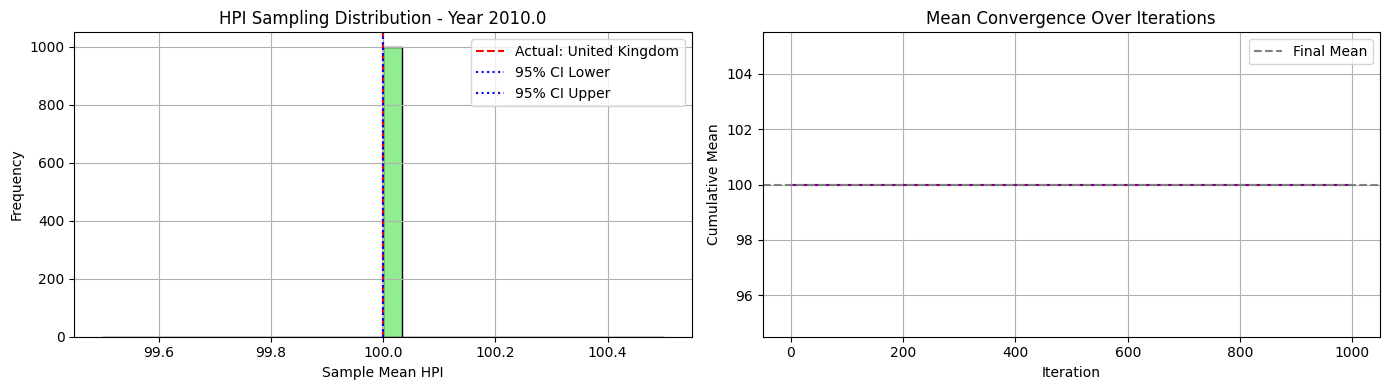

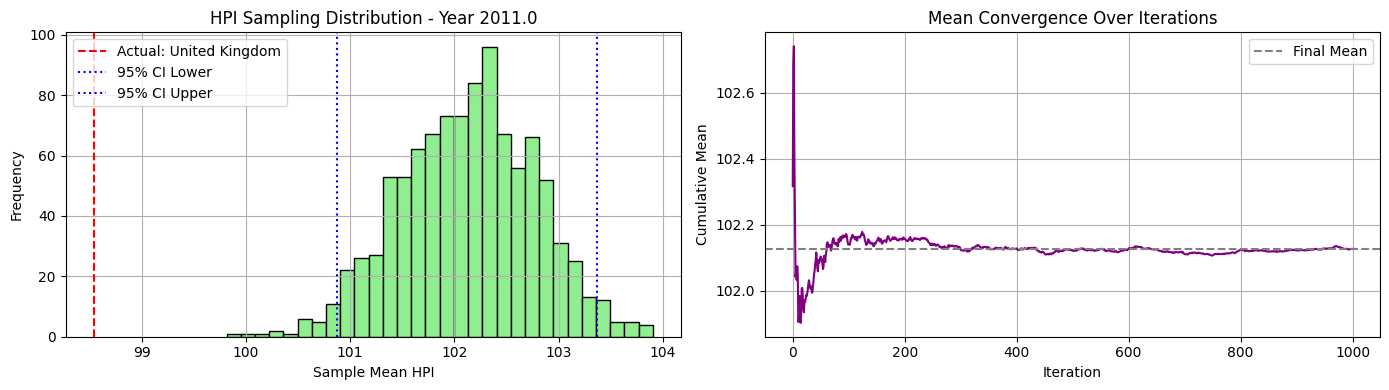

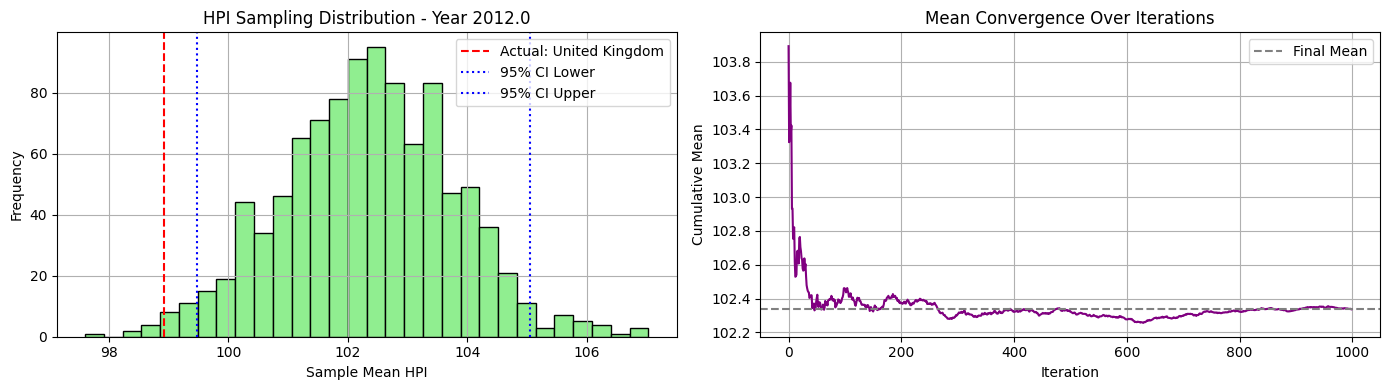

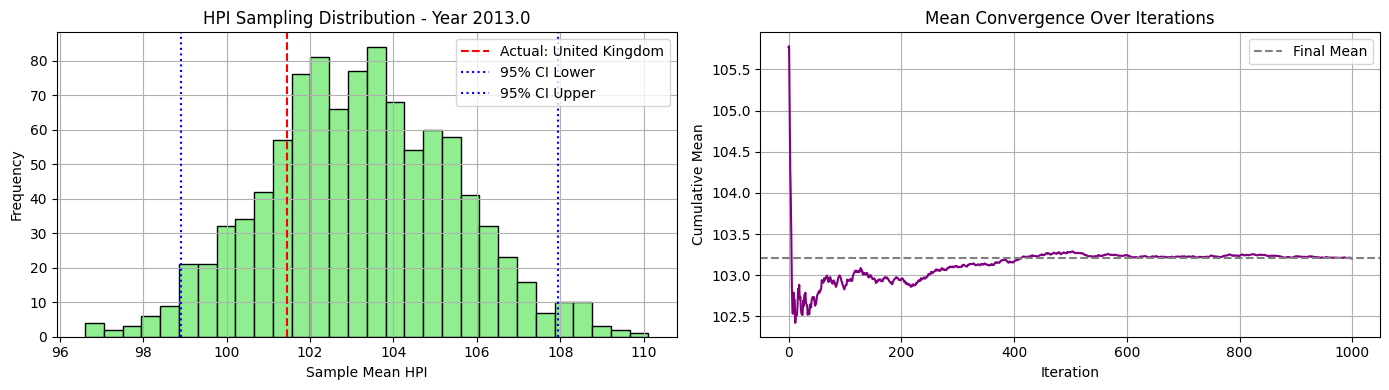

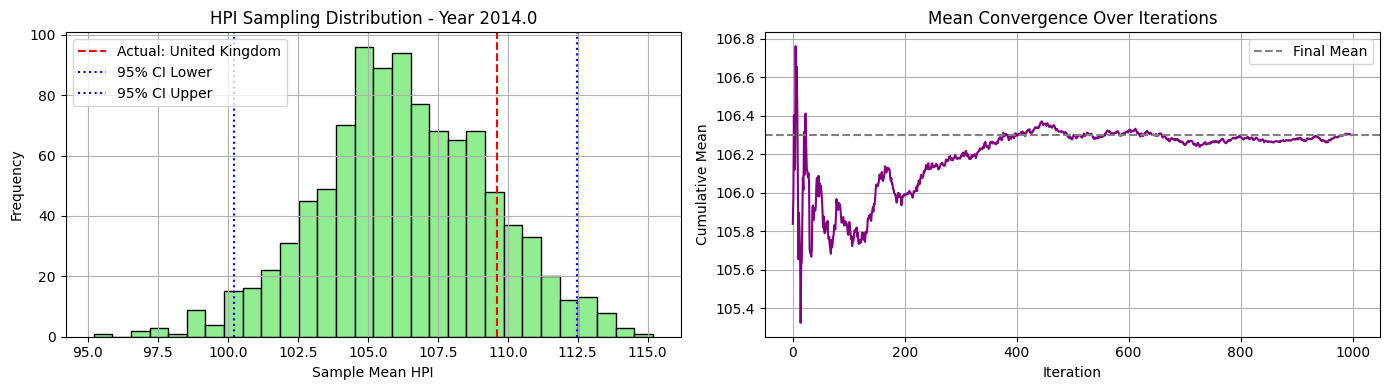

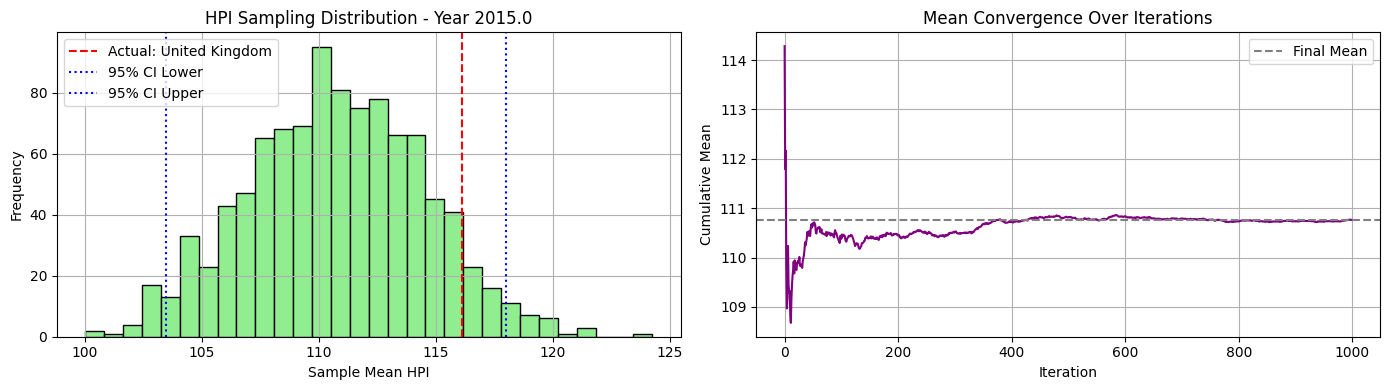

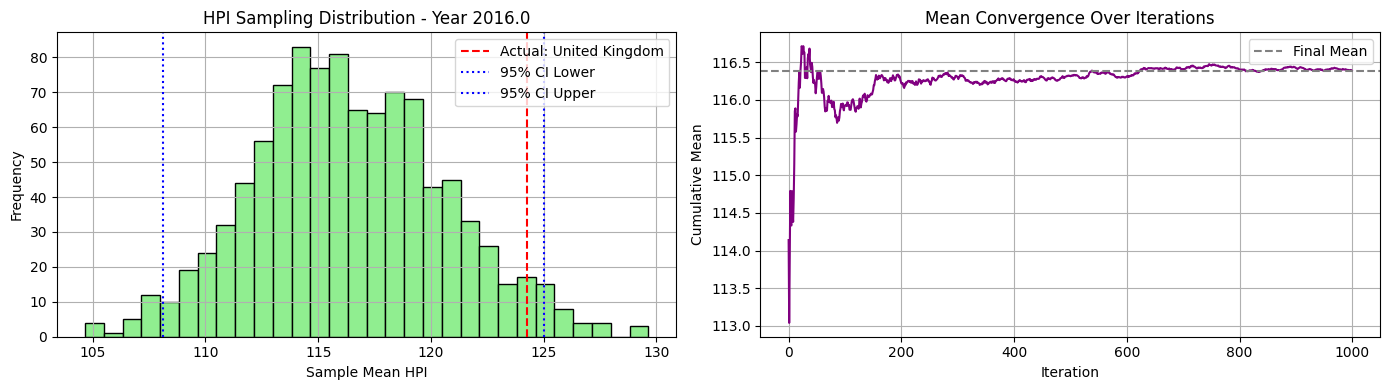

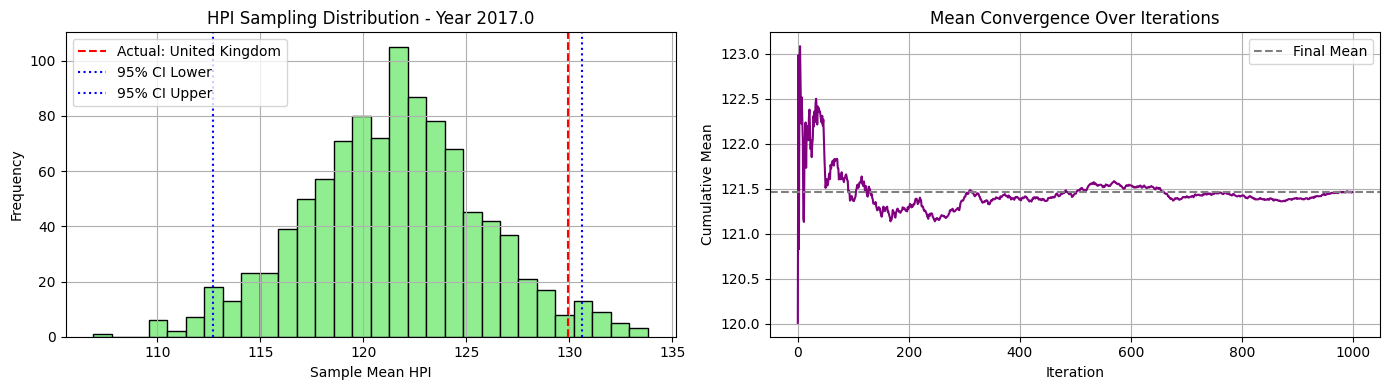

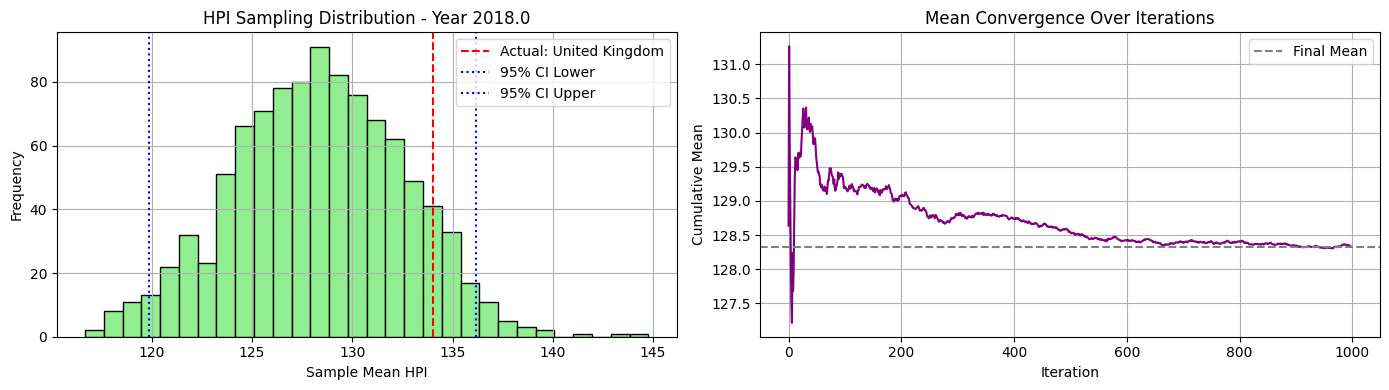

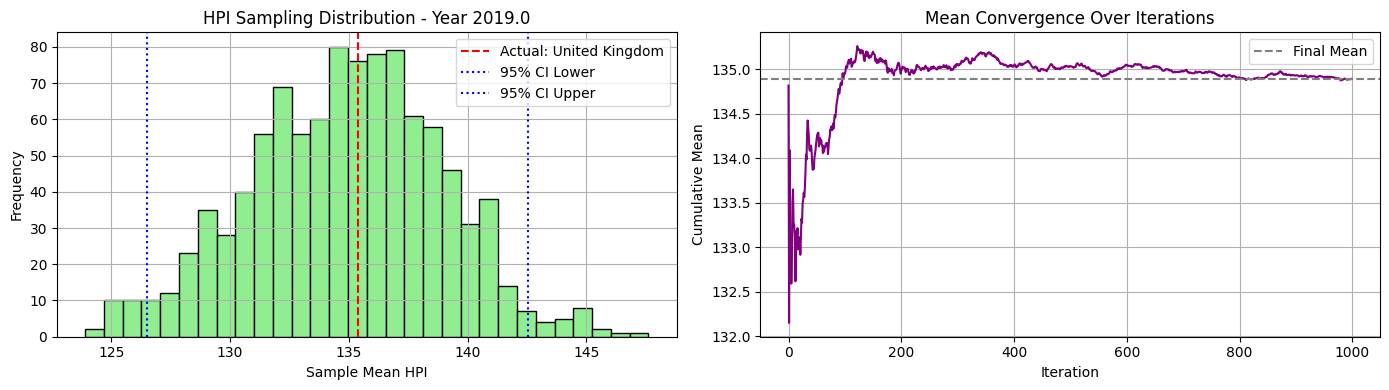

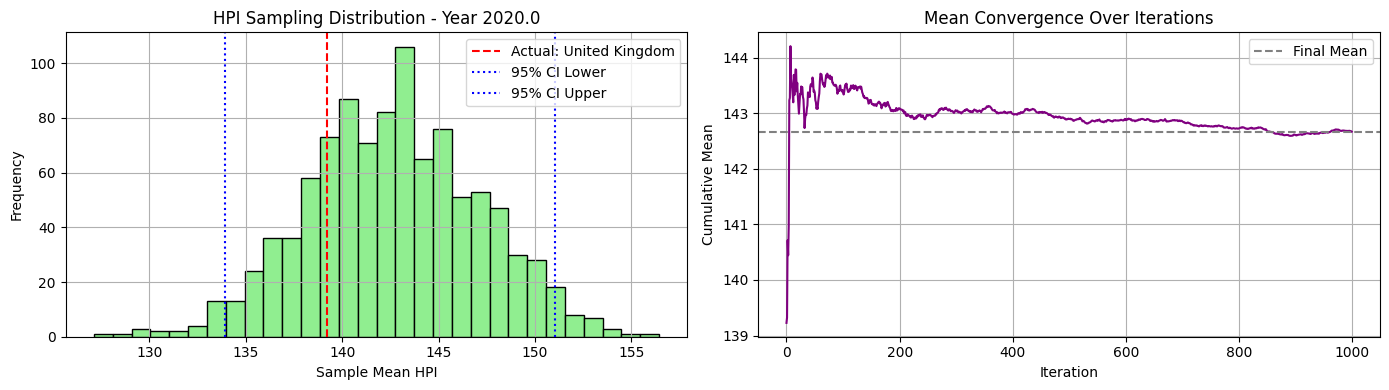

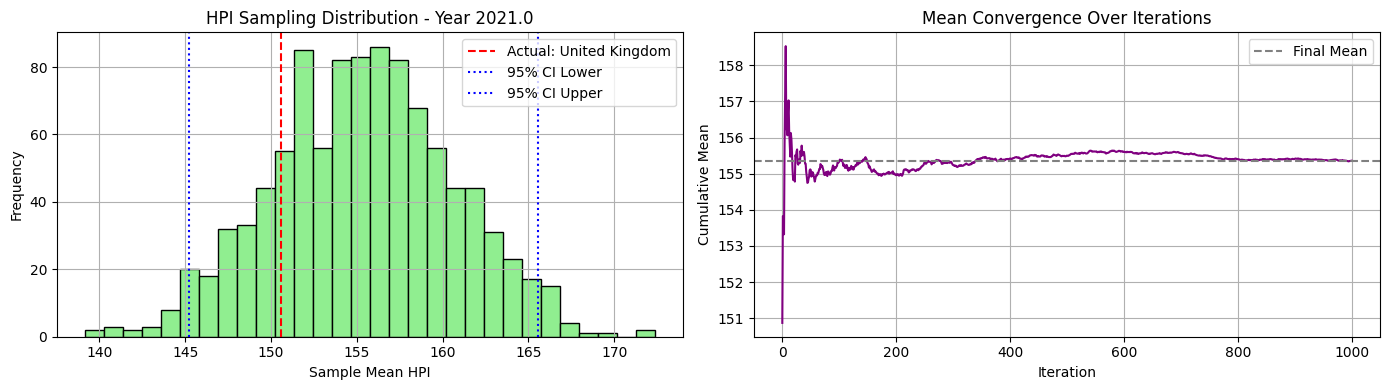

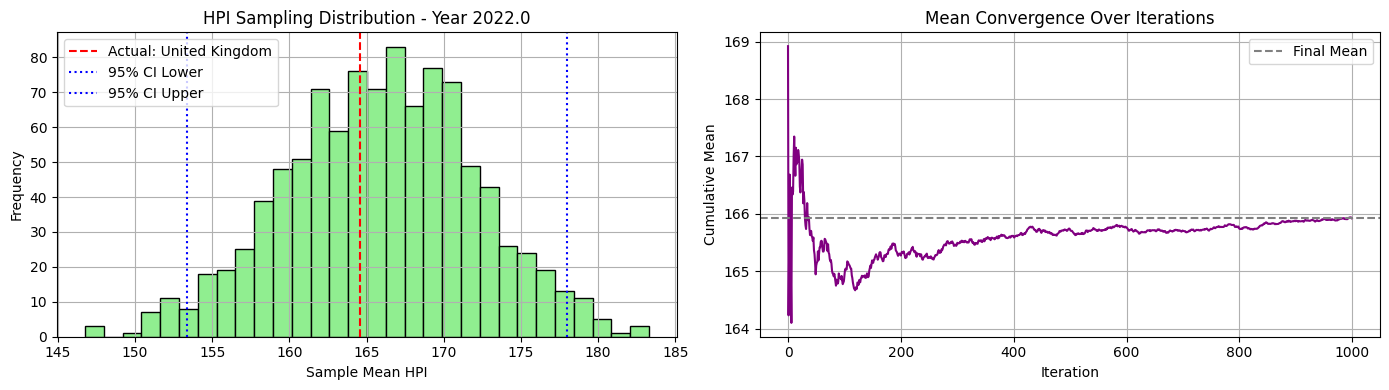

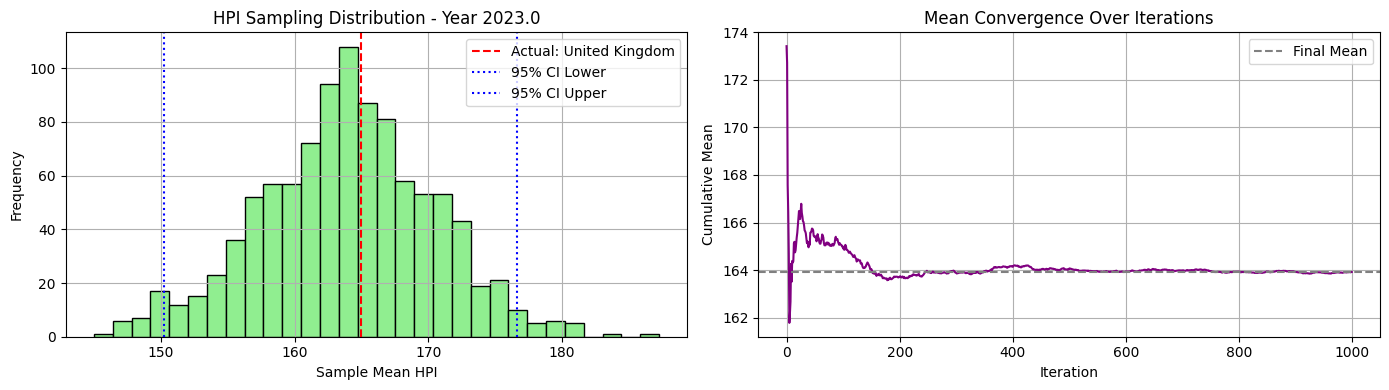

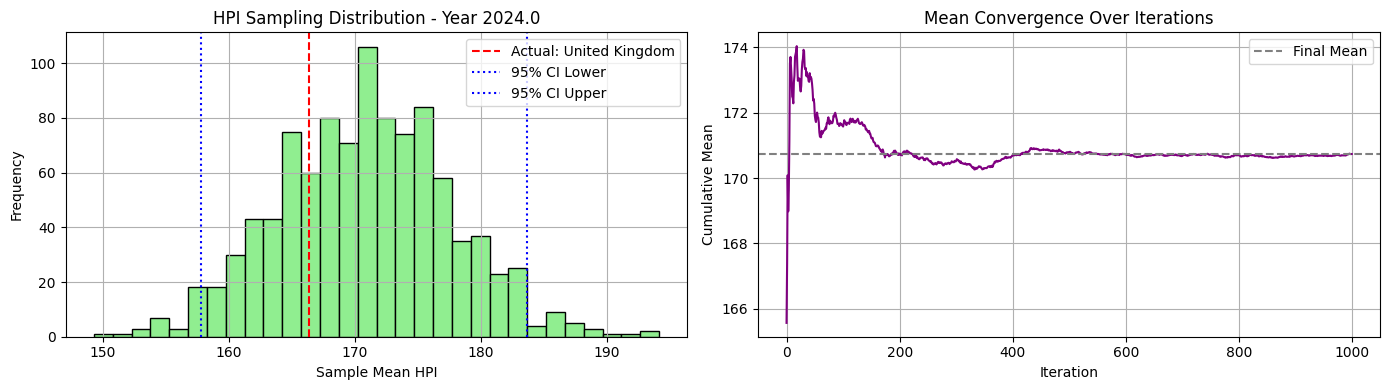

In [96]:
avg_mse_00, avg_mae_00, best_country_00, yearly_bootstrap_means_00, yearly_mean_00 = evaluate_cluster_sampling_errors(hpi_c2_ni20_maxi500_5_win1, c2_ni20_maxi500_5, cluster_id=0)

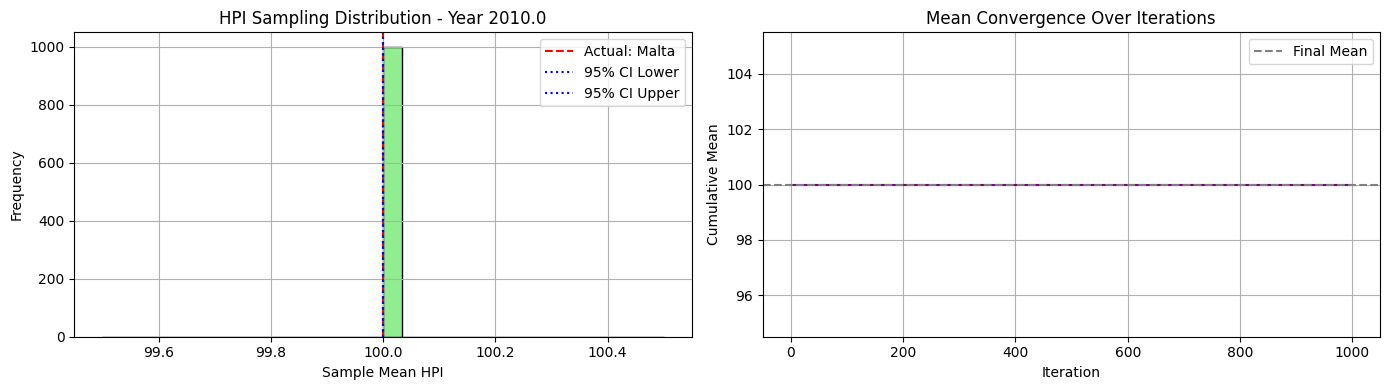

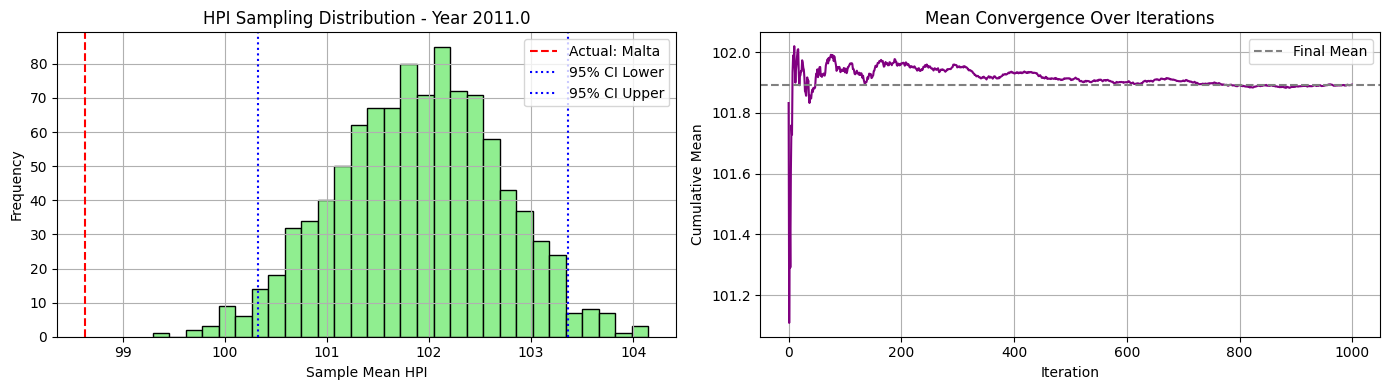

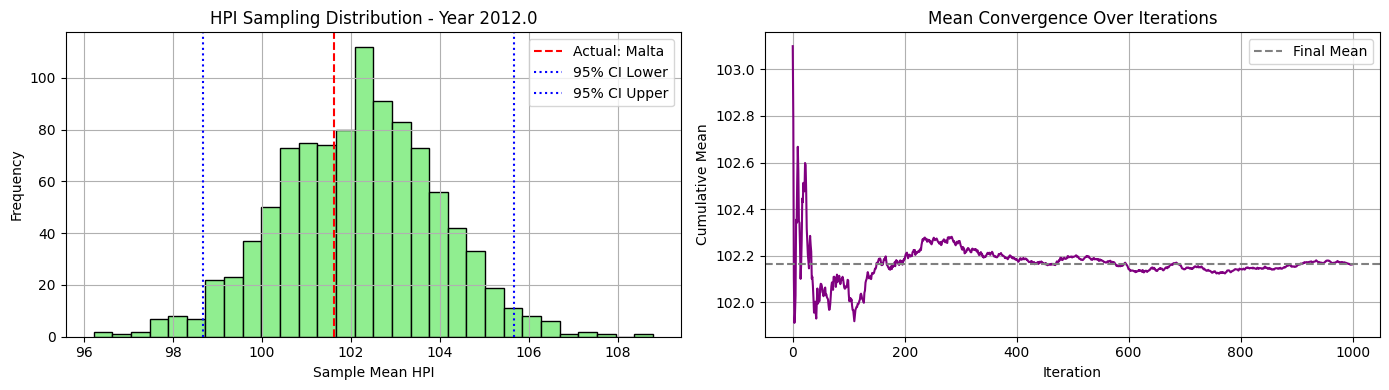

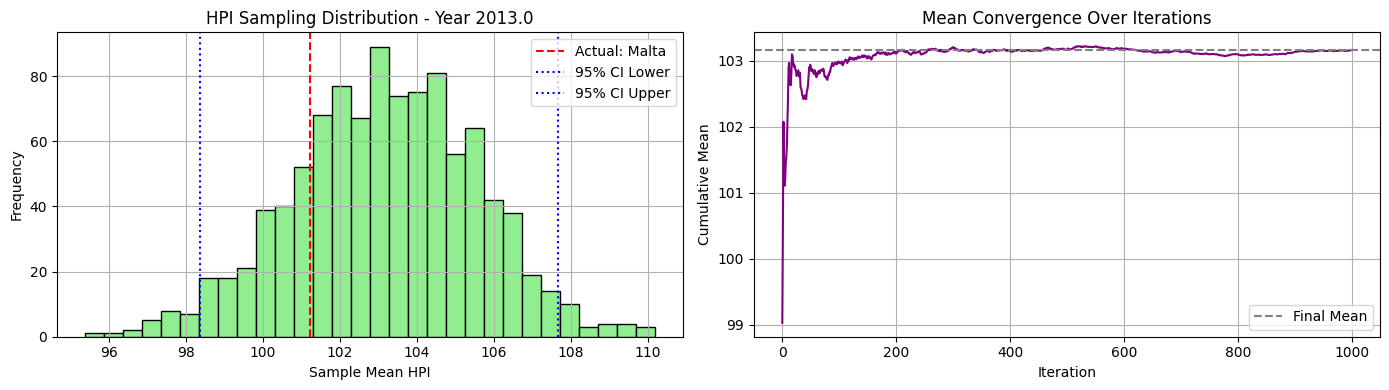

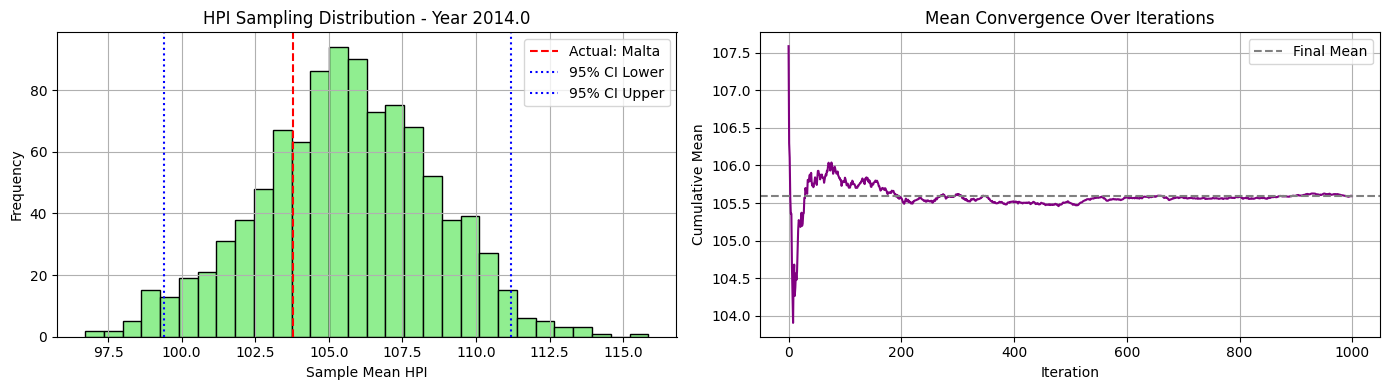

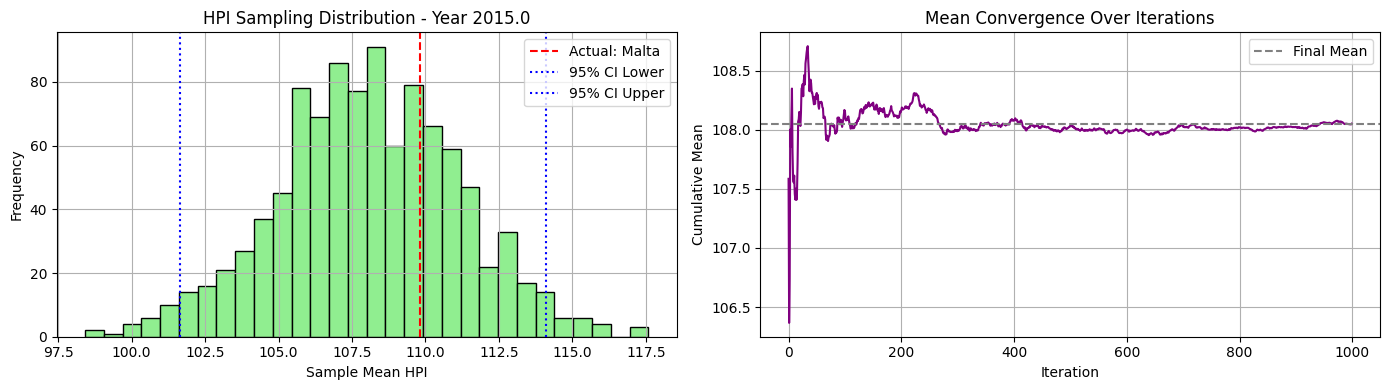

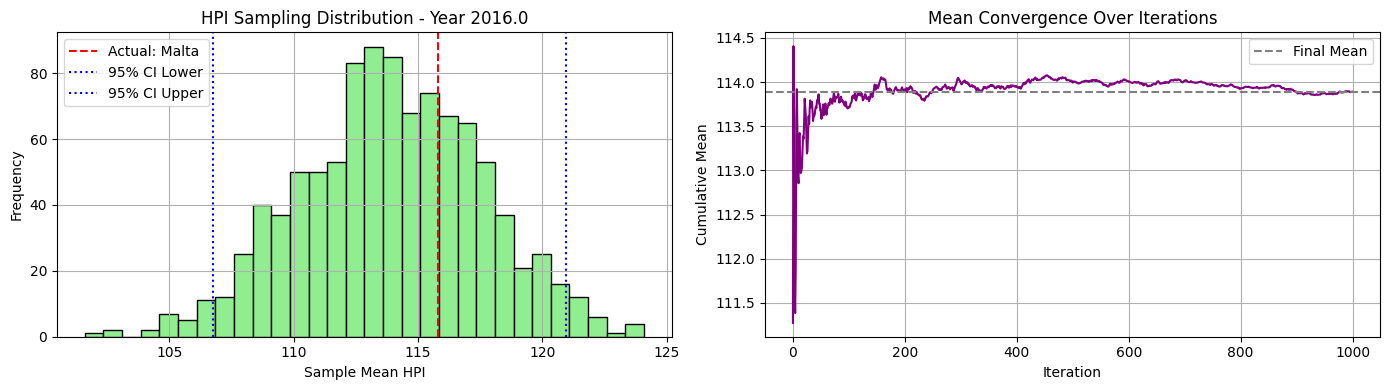

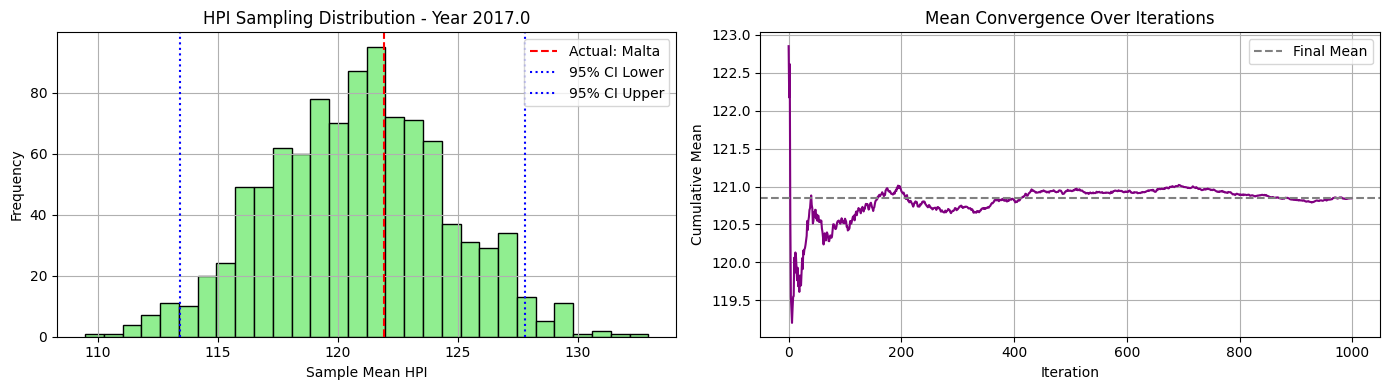

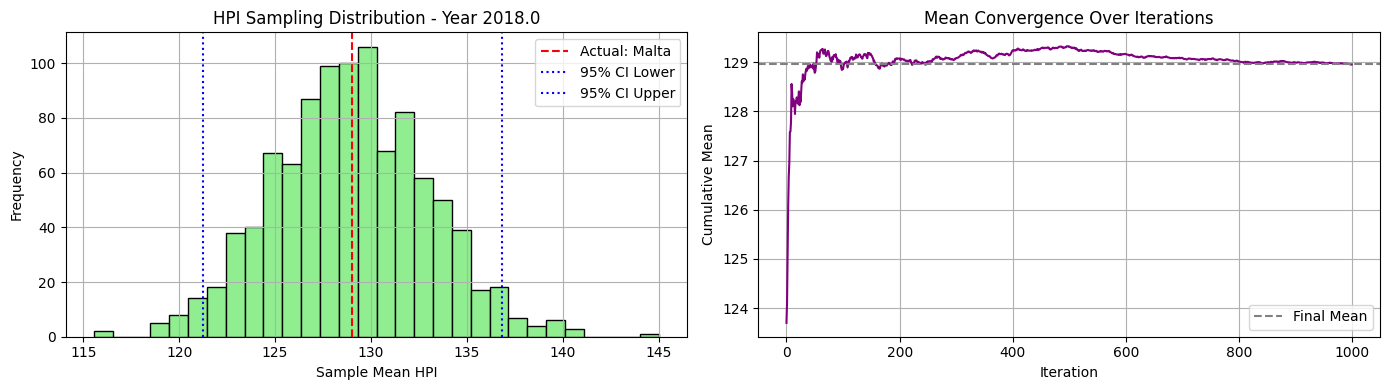

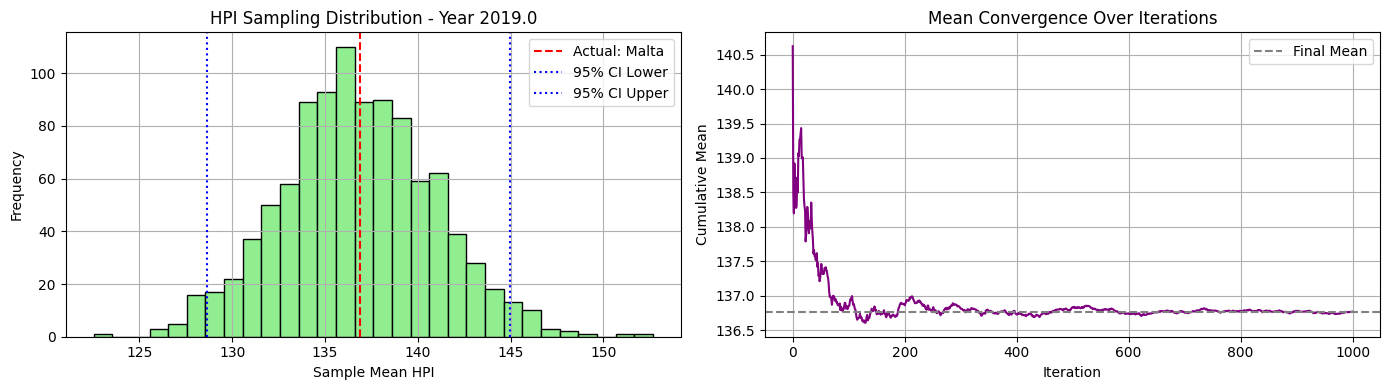

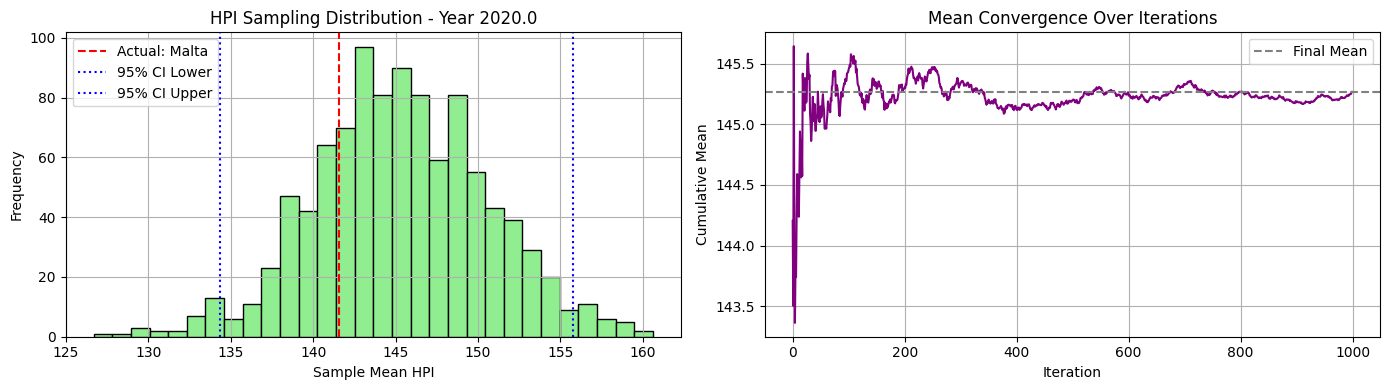

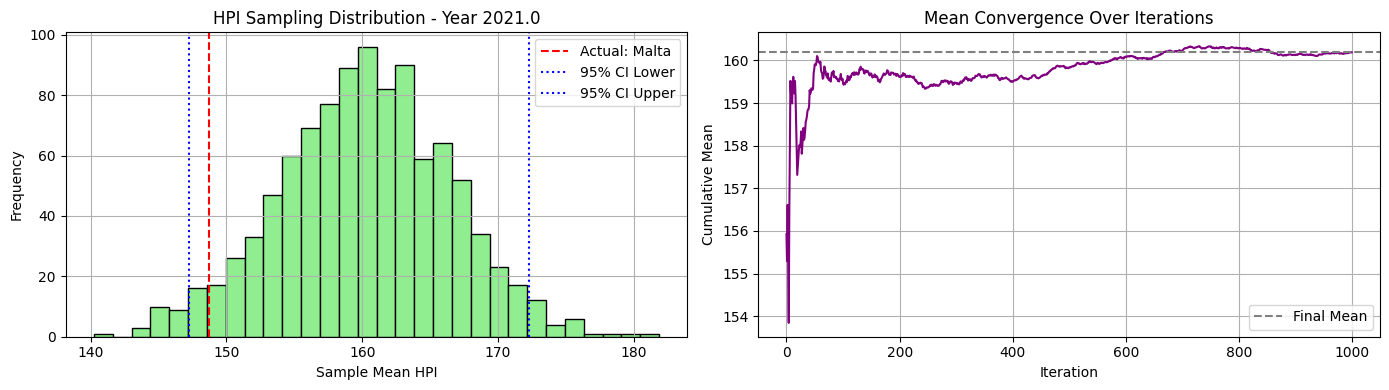

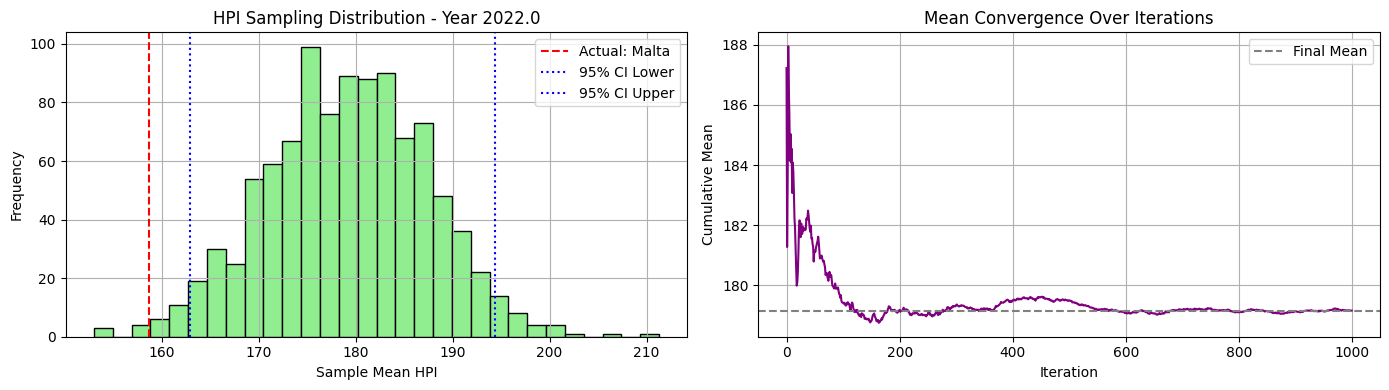

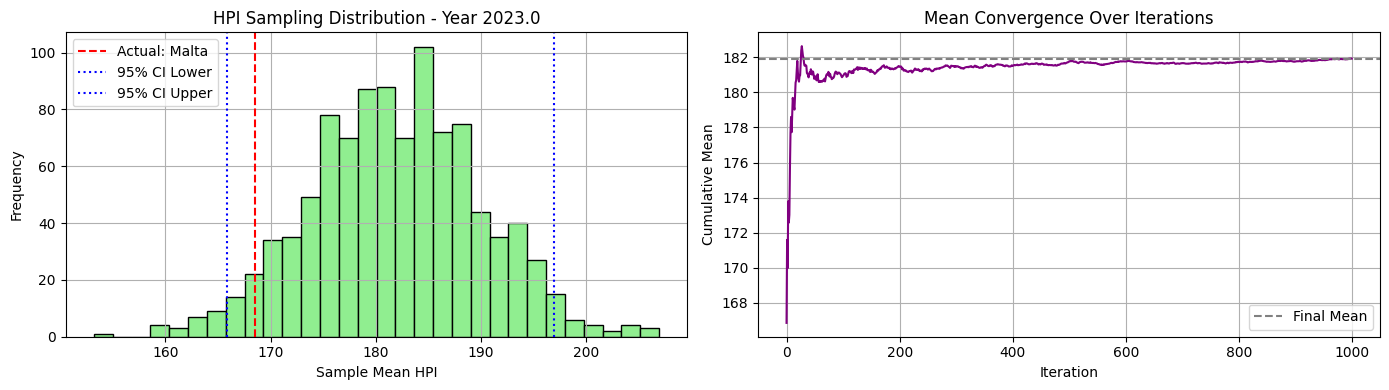

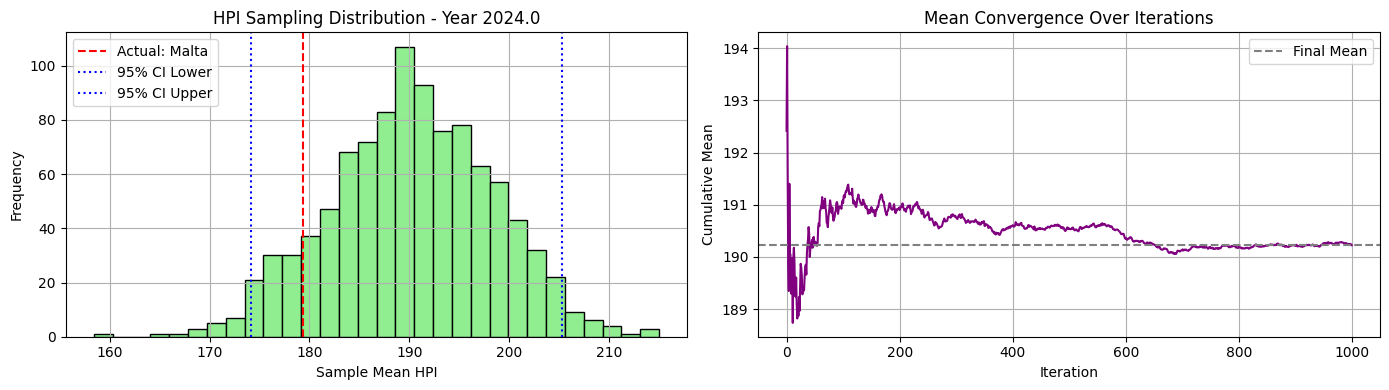

In [97]:
avg_mse_01, avg_mae_01, best_country_01, yearly_bootstrap_means_01, yearly_mean_01 = evaluate_cluster_sampling_errors(hpi_c2_ni20_maxi500_5_win1, c2_ni20_maxi500_5, cluster_id=1)

### Compute metrics
* Compute MSE from synthetic data versus the real one from the country excluded
* Compute MAE from synthetic data versus the real one from the country excluded

In [98]:
errors2 = {
    'cluster_0': [avg_mse_00, avg_mae_00],
    'cluster_1': [avg_mse_01, avg_mae_01]
}

In [99]:
# Convertir a DataFrame
df_errors2 = pd.DataFrame.from_dict(errors2, orient='index', columns=['Average MSE', 'Average MAE'])

# Formatear valores con 4 decimales
df_errors2 = df_errors2.round(4)

# Imprimir tabla
print("\n📊 Cluster Sampling Error Summary:")
print(df_errors2)


📊 Cluster Sampling Error Summary:
           Average MSE  Average MAE
cluster_0     609.6153      18.8955
cluster_1     765.9750      21.1222


In [100]:
variances2 = calculate_hpi_variance_by_cluster(hpi_c2_ni20_maxi500_5_win1, c2_ni20_maxi500_5)
for cluster_id, var in variances2.items():
    print(f"Cluster {cluster_id}: Avg HPI Variance = {var:.4f}")

Cluster 0: Avg HPI Variance = 553.9215
Cluster 1: Avg HPI Variance = 705.8342


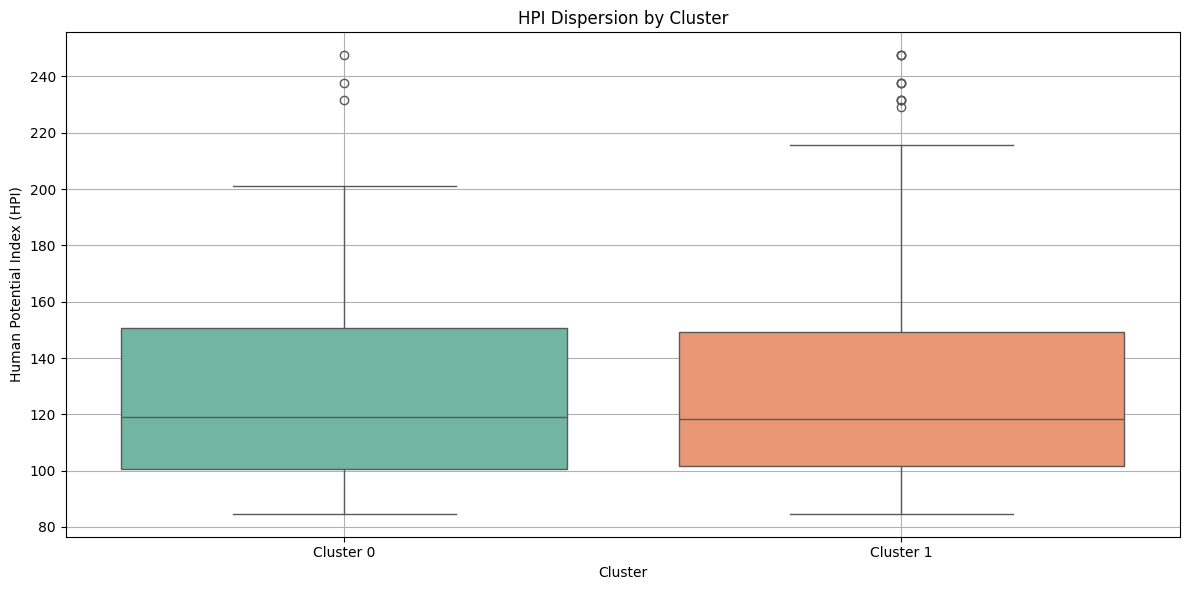

In [101]:
plot_hpi_dispersion_by_cluster(hpi_c2_ni20_maxi500_5_win1, c2_ni20_maxi500_5)

In [102]:
iqr_percent2= percentage_points_within_iqr_by_cluster(hpi_c2_ni20_maxi500_5_win1, c2_ni20_maxi500_5)
print(iqr_percent2)

{np.int32(0): np.float64(49.09), np.int32(1): np.float64(56.92)}


### Log performance of the experiment
* Import dataframe for the logs
* Define the hyperparameter for introduce the results
* Export the dataframe

In [103]:
log_df = pd.read_parquet('../data/log_performance/new_log_performance.parquet')

In [104]:
pd.set_option('display.max_columns', None)

In [105]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1119.271800,23.643200,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,239.0,177.0,NaN,NaN
2,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1146.197900,24.224467,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,128.0,143.0,145.0,NaN
3,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"StandardScaler, log transformation",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1090.520600,23.289700,hypothesis_test_015,None,None,956.43,1130.45,NaN,NaN,256.0,145.0,NaN,NaN
4,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"StandardScaler, log transformation",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1814.632583,29.398783,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,49.0,57.0,17.0,130.0
5,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,686.638600,19.998050,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,81.0,111.0,NaN,NaN


In [107]:
new_entry2 = {
    'experiment_name': 'kmeans_++_2c_pareto_countries_exclude',
    'experiment_date': '2025-09-15 20:48',
    'premacroecon_conversion_transform': None,
    'countries_used_for_clustering': 26,
    'clustering_model': 'KMeans',
    'n_clusters': 2,
    'init_method': 'k-means++',
    'n_init': 20,
    'max_iter': 500,
    'random_state': 42,
    'used_elbow_method': True,
    'used_silhouette_score': True,
    'used_2nd_derivate_for_inflection': True,
    'silhouette_score': silhoutte_c2_ni20_maxi500,
    'transformations_clustering': 'Winsorization x5, log transformation, Robust Scaler',
    'outliers_handling_clustering': 'Winsorization x5, Delete Countries x27 Pareto Rule',
    'used_all_variables_for_clustering': True,
    'used_pca_for_clustering': False,
    'transformations_sampling': 'Winsorization x2, rounding, Delete Countries x27 Pareto Rule',
    'outliers_handling_sampling': 'Winsorization x2, Delete Countries x27 Pareto Rule, Winsorization x2',
    'sampling_method': 'bootstrap',
    'sampling_seed': None,
    'excluded_countries_count': 26,
    'mse_score': df_errors2['Average MSE'].mean(),
    'mae_score': df_errors2['Average MAE'].mean(),
    'source_notebook': 'hypothesis_test_017',
    'pca_ratio_sum': None,
    'pca_ratio_values': None,
    'Variance_Cluster_0': round(float(variances2[0]),2),
    'Variance_Cluster_1': round(float(variances2[1]),2),
    'Variance_Cluster_2': None,
    'Variance_Cluster_3': None,
    'IQR_Count_Cluster_0':int(iqr_percent2[0]),
    'IQR_Count_Cluster_1':int(iqr_percent2[1]),
    'IQR_Count_Cluster_2': None,
    'IQR_Count_Cluster_3': None   
}

In [108]:
log_df = pd.concat([log_df, pd.DataFrame([new_entry2])], ignore_index=True)

C:\Users\lucas\AppData\Local\Temp\ipykernel_19296\3551463810.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  log_df = pd.concat([log_df, pd.DataFrame([new_entry2])], ignore_index=True)


In [109]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1119.271800,23.643200,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,239.0,177.0,NaN,NaN
2,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1146.197900,24.224467,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,128.0,143.0,145.0,NaN
3,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"StandardScaler, log transformation",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1090.520600,23.289700,hypothesis_test_015,None,None,956.43,1130.45,NaN,NaN,256.0,145.0,NaN,NaN
4,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"StandardScaler, log transformation",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1814.632583,29.398783,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,49.0,57.0,17.0,130.0
5,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,686.638600,19.998050,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,81.0,111.0,NaN,NaN
6,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN


In [110]:
# Supongamos que quieres eliminar la fila con índice 5
log_df = log_df.drop(index=5)

# Luego reseteas el índice para que quede consecutivo
log_df = log_df.reset_index(drop=True)

In [111]:
log_df

,experiment_name,experiment_date,premacroecon_conversion_transform,countries_used_for_clustering,clustering_model,n_clusters,init_method,n_init,max_iter,random_state,used_elbow_method,used_silhouette_score,used_2nd_derivate_for_inflection,silhouette_score,transformations_clustering,outliers_handling_clustering,used_all_variables_for_clustering,used_pca_for_clustering,transformations_sampling,outliers_handling_sampling,sampling_method,sampling_seed,excluded_countries_count,mse_score,mae_score,source_notebook,pca_ratio_sum,pca_ratio_values,Variance_Cluster_0,Variance_Cluster_1,Variance_Cluster_2,Variance_Cluster_3,IQR_Count_Cluster_0,IQR_Count_Cluster_1,IQR_Count_Cluster_2,IQR_Count_Cluster_3
0,baseline_kmeans_random_3_countries_exclude,2025-09-13 20:55,None,53,KMeans,3,random,10.0,100.0,42.0,False,False,0,NaN,"StandardScaler, log transformation",None,True,False,"Winsorization, rounding",Winsorization,bootstrap,None,52.0,1691.177800,30.303867,hypothesis_test_07-percent_exclusion,None,None,1050.94,1033.31,2407.89,NaN,143.0,239.0,36.0,NaN
1,kmeans_++_2c_countries_exclude,2025-09-14 11:38,None,53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.399803,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1119.271800,23.643200,hypothesis_test_013,None,None,1177.08,975.18,NaN,NaN,239.0,177.0,NaN,NaN
2,kmeans_++_3c_countries_exclude,2025-09-14 11:40,None,53,KMeans,3,k-means++,20.0,500.0,42.0,True,True,1,0.310983,"StandardScaler, log transformation",Winsorization x6,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1146.197900,24.224467,hypothesis_test_013,None,None,1257.22,1050.94,927.59,NaN,128.0,143.0,145.0,NaN
3,kmeans_++_2c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.131965,"StandardScaler, log transformation",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1090.520600,23.289700,hypothesis_test_015,None,None,956.43,1130.45,NaN,NaN,256.0,145.0,NaN,NaN
4,kmeans_++_6c_pre-coversion_countries_exclude,2025-09-14 22:15,"Winsorization, RobustScaler",53,KMeans,6,k-means++,20.0,500.0,42.0,True,True,1,0.096031,"StandardScaler, log transformation",Winsorization x8,True,False,"Winsorization x2, rounding",Winsorization x2,bootstrap,None,52.0,1814.632583,29.398783,hypothesis_test_015,None,None,1228.13,1590.76,3058.83,871.95,49.0,57.0,17.0,130.0
5,kmeans_++_2c_pareto_countries_exclude,2025-09-15 20:48,None,26,KMeans,2,k-means++,20.0,500.0,42.0,True,True,1,0.408223,"Winsorization x5, log transformation, Robust S...","Winsorization x5, Delete Countries x27 Pareto ...",True,False,"Winsorization x2, rounding, Delete Countries x...","Winsorization x2, Delete Countries x27 Pareto ...",bootstrap,None,26.0,687.795150,20.008850,hypothesis_test_017,None,None,553.92,705.83,NaN,NaN,49.0,56.0,NaN,NaN


In [112]:
log_df.to_parquet('../data/log_performance/new_log_performance.parquet')